#  Indian Sign Language Recognition Using Deep Learning

## Project Title
**Indian Sign Language Recognition Using Deep Learning**

## Project Description
This project develops an image classification system for recognizing Indian Sign Language (ISL) hand signs. The images are organized into class-wise folders and are processed using Computer Vision and Deep Learning techniques.

The project covers dataset exploration, image preprocessing, Deep Learning model development, model comparison, traditional Machine Learning using extracted features, final evaluation, Grad-CAM visualization and ROC-AUC analysis.

## Project Objective
- Preprocess Indian Sign Language images.
- Explore the dataset using EDA.
- Build and compare CNN-based Deep Learning models.
- Use MobileNetV2 transfer learning for sign classification.
- Compare traditional Machine Learning algorithms such as SVM, KNN and Random Forest.
- Evaluate the final model using accuracy, precision, recall and F1-score.

## Notebook Workflow
**Google Drive → Import Libraries → Dataset → EDA → Image Preprocessing → Deep Learning Models → Model Comparison → Feature Extraction → Machine Learning Models → Final Evaluation → Confusion Matrix → Grad-CAM → ROC/AUC → Conclusion → Future Scope**

> **Colab:** Run the notebook from top to bottom so that all variables, generators and saved models are available when later cells are executed.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#  Import the Required Libraries

## Description
The required Python libraries are imported for data handling, image processing, visualization, Deep Learning and Machine Learning.

**Main libraries:** NumPy, Pandas, Matplotlib, Seaborn, OpenCV, TensorFlow/Keras and Scikit-learn.

These libraries are used throughout the notebook for dataset analysis, model training and evaluation.


In [ ]:
# Import all the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler,label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score,roc_curve,auc


#  Connect Google Drive and Set the Dataset Path

## Description
Google Drive is mounted so that the Indian Sign Language image dataset can be accessed directly from Google Colab.

The dataset path is then checked before starting the analysis.


In [ ]:
data_path = ('/content/drive/MyDrive/IndisignLanguageRecognition/Data')
if not os.path.exists(data_path):
  print(f"Path not found: '{data_path}'")
elif os.path.isfile(data_path):
  data = pd.read_csv(data_path)
  print(f"Shape :  {data.shape}")
elif os.path.isdir(data_path):
  print(f"Directory Content { os.listdir(data_path)}")

Directory Content ['E', 'B', 'A', 'F', 'L', 'C', 'K', 'D', 'I', 'O', 'G', 'N', 'H', 'Q', 'P', 'M', 'R', 'S', 'Y', 'T', 'X', 'W', 'V', 'U']


#  Dataset Overview

## Description
The dataset is organized into separate folders, where each folder represents one Indian Sign Language class.

This cell checks the number of classes, total images and image count available in each class.


In [ ]:
# Check the number of classes , images and count the images per class
classes = os.listdir(data_path)
print('Classes:',classes)
print('Total Classes:',(len(classes)))
for cls in classes:
  print(cls,".",len(os.listdir(os.path.join(data_path,cls))))

Classes: ['E', 'B', 'A', 'F', 'L', 'C', 'K', 'D', 'I', 'O', 'G', 'N', 'H', 'Q', 'P', 'M', 'R', 'S', 'Y', 'T', 'X', 'W', 'V', 'U']
Total Classes: 24
E . 243
B . 259
A . 242
F . 226
L . 182
C . 247
K . 245
D . 147
I . 179
O . 229
G . 241
N . 237
H . 116
Q . 216
P . 234
M . 235
R . 211
S . 229
Y . 251
T . 216
X . 202
W . 128
V . 122
U . 135


#  Basic Class Information

## Description
The class folders are sorted and basic information about the dataset is displayed.

This step confirms the class labels that will be used as the target classes during model training.


In [ ]:
# Check Basic class information
classes = sorted(os.listdir(data_path))
print(f'Total Classes:,{len(classes)}')
print(f'Classes:,{classes}')


Total Classes:,24
Classes:,['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


# Count Images in Each Class

## Description
The number of images in every class is calculated.

This is useful for understanding whether the dataset is balanced or whether some classes contain significantly more images than others.


In [ ]:
# Check the count of image per class
class_counts = {}
for cls in classes:
  cls_path = os.path.join(data_path,cls)
  class_counts[cls] = len(os.listdir(cls_path))
  print(f'{cls} : {class_counts[cls]} images')
print(f'\n Total Images : {sum(class_counts.values())}')
print(f'Min images in a class : {min(class_counts.values())}')
print(f'Max images in a class : {max(class_counts.values())}')

A : 242 images
B : 259 images
C : 247 images
D : 147 images
E : 243 images
F : 226 images
G : 241 images
H : 116 images
I : 179 images
K : 245 images
L : 182 images
M : 235 images
N : 237 images
O : 229 images
P : 234 images
Q : 216 images
R : 211 images
S : 229 images
T : 216 images
U : 135 images
V : 122 images
W : 128 images
X : 202 images
Y : 251 images

 Total Images : 4972
Min images in a class : 116
Max images in a class : 259


# EDA – Class Distribution Analysis

## Description
The class distribution is visualized using a bar chart.

The project dataset contains **4,972 images across 24 classes**. The number of images differs between classes, so the distribution is checked before model training.


Class Distribution:


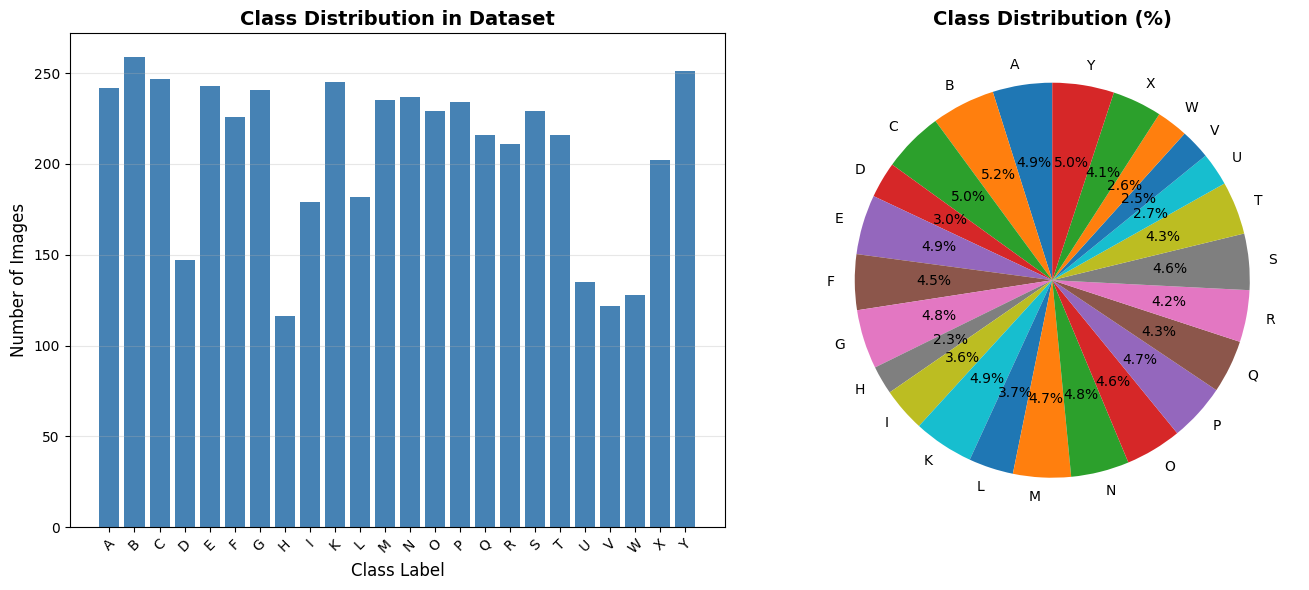


Total images: 4972
Number of classes: 24
Images per class - Min: 116, Max: 259, Mean: 207.2

Class balance ratio: 2.23:1
⚠️ Data imbalance detected - consider class weights or augmentation


In [ ]:
# 1. Class Distribution Analysis
print("Class Distribution:")

# Use the 'class_counts' dictionary computed in a previous cell (6CXObf81rKej)
# Convert the dictionary to a pandas Series for consistent plotting logic
class_counts_series = pd.Series(class_counts).sort_index()
class_labels = list(class_counts_series.index)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.bar(range(len(class_counts_series)), class_counts_series.values, color='steelblue')
plt.xlabel('Class Label', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.title('Class Distribution in Dataset', fontsize=14, fontweight='bold')
plt.xticks(range(len(class_counts_series)), class_labels, rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
percentages = (class_counts_series.values / class_counts_series.sum() * 100)
plt.pie(percentages, labels=class_labels, autopct='%1.1f%%', startangle=90)
plt.title('Class Distribution (%)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nTotal images: {class_counts_series.sum()}")
print(f"Number of classes: {len(class_counts_series)}")
print(f"Images per class - Min: {class_counts_series.min()}, Max: {class_counts_series.max()}, Mean: {class_counts_series.mean():.1f}")
print(f"\nClass balance ratio: {class_counts_series.max() / class_counts_series.min():.2f}:1")

if class_counts_series.max() / class_counts_series.min() > 2:
    print("⚠️ Data imbalance detected - consider class weights or augmentation")
else:
    print("✓ Classes are reasonably balanced")


# EDA – Sample Image Visualization

## Description
Sample images from different Indian Sign Language classes are displayed.

This helps visually verify that the images are correctly stored and that the class labels correspond to the expected hand signs.


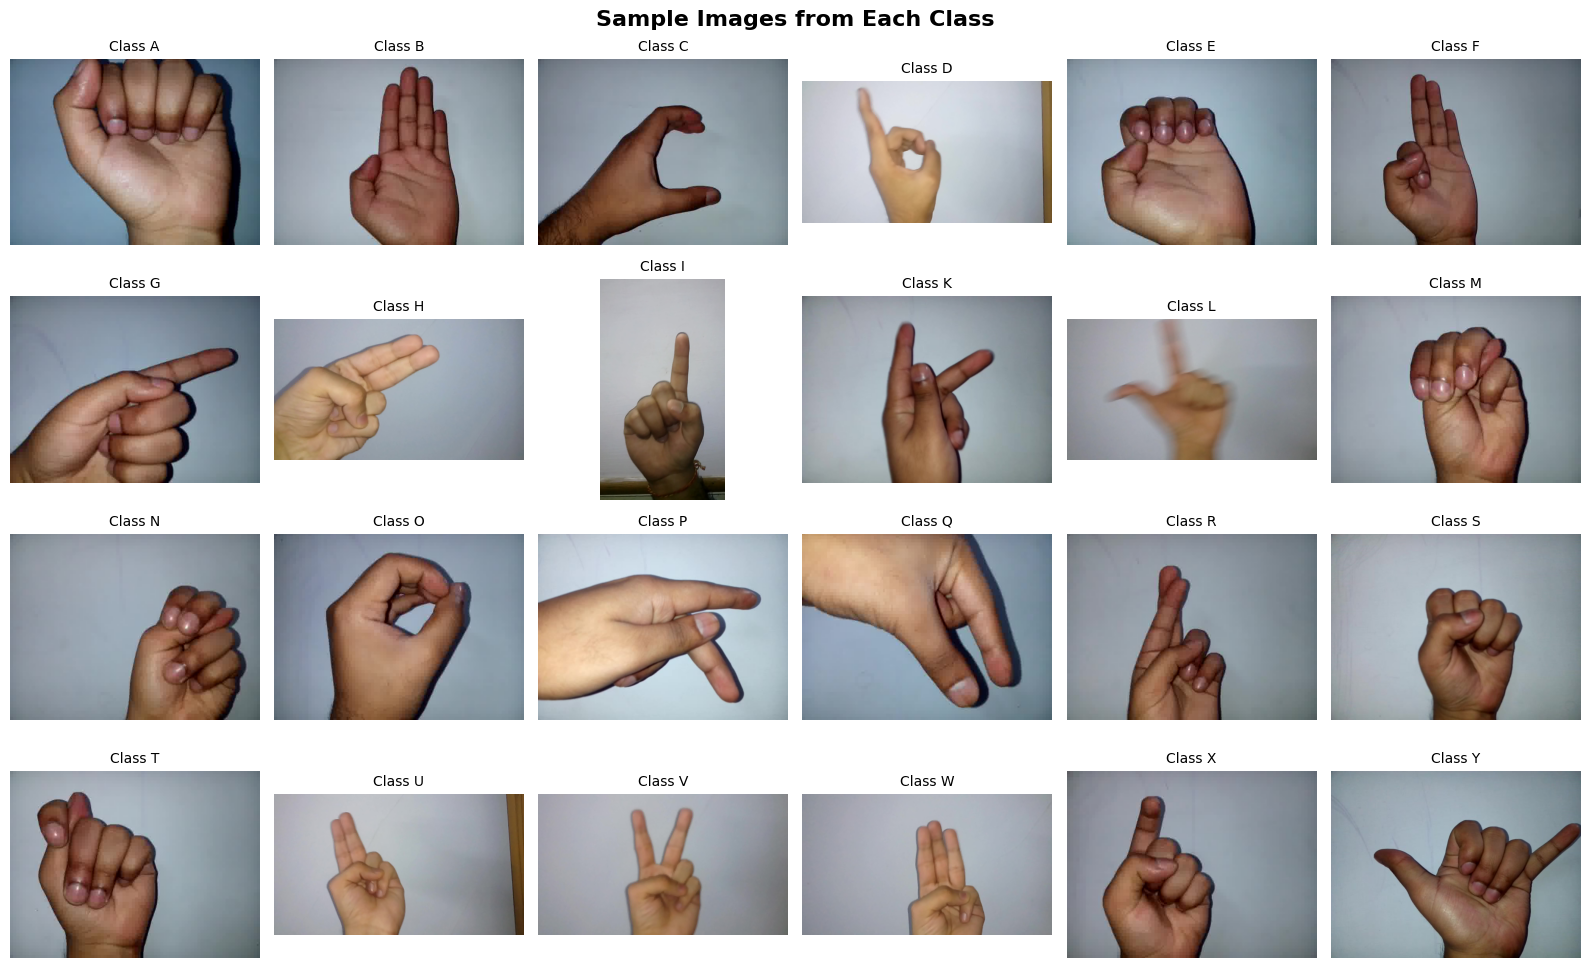

In [ ]:
#2. Sample Images Visualization
import random
import matplotlib.pyplot as plt # Ensure plt is imported for plotting
from PIL import Image # Ensure Image is imported for loading images
import os # Ensure os is imported for path operations

fig, axes = plt.subplots(4, 6, figsize=(16, 10))
fig.suptitle('Sample Images from Each Class', fontsize=16, fontweight='bold')

# Assuming 'classes' and 'data_path' are available from previous cells
# Use these to directly load sample images for visualization
for idx, class_name in enumerate(classes[:24]): # Limit to first 24 classes if more exist for display grid
    if idx < len(classes):
        cls_path = os.path.join(data_path, class_name)
        if os.path.exists(cls_path) and os.listdir(cls_path):
            sample_image_file = random.choice(os.listdir(cls_path))
            img_path = os.path.join(cls_path, sample_image_file)
            img = Image.open(img_path)

            ax = axes[idx // 6, idx % 6]
            ax.imshow(img)
            ax.set_title(f'Class {class_name}', fontsize=10)
            ax.axis('off')
        else:
            # Handle cases where a class directory might be empty or missing
            ax = axes[idx // 6, idx % 6]
            ax.text(0.5, 0.5, f"No images in {class_name}", horizontalalignment='center', verticalalignment='center')
            ax.axis('off')
    else:
        # Fill remaining subplots if there are fewer than 24 classes
        ax = axes[idx // 6, idx % 6]
        ax.axis('off')

plt.tight_layout()
plt.show()

#  EDA – Class Imbalance Analysis

## Description
The class counts are visualized again to identify possible class imbalance.

The notebook reports a variation in the number of images per class. Data augmentation is therefore used later to improve model generalization.


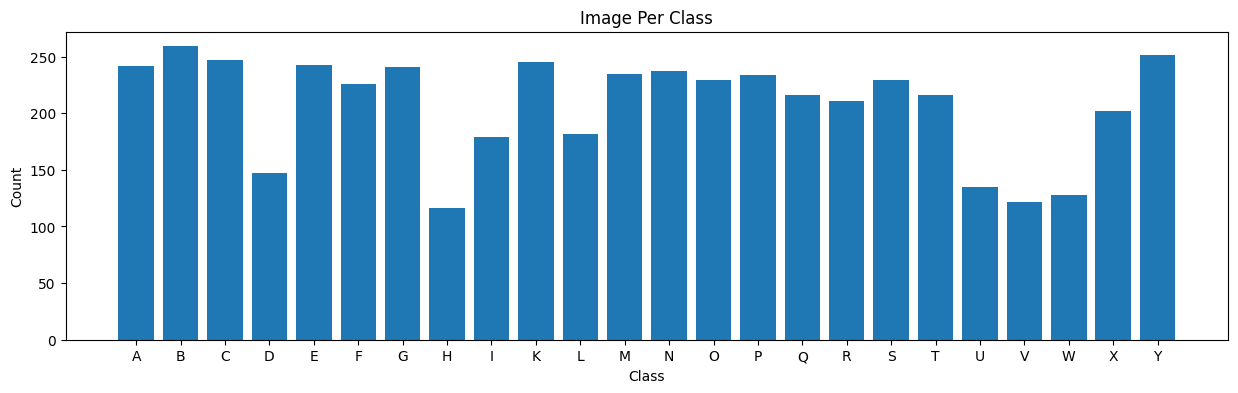

In [ ]:
# Check the class imabalance for all the classes
plt.figure(figsize=(15,4))
plt.bar(class_counts.keys(),class_counts.values())
plt.title('Image Per Class')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

#  EDA – Image Size Analysis

## Description
The dimensions of the images are checked.

The dataset contains images with different resolutions, so all images need to be resized to a common input size before they are passed to the Deep Learning models.


In [ ]:
# Check the image size
sizes = set()
for cls in classes:
  cls_path = os.path.join(data_path,cls)
  sample_img = os.path.join(cls_path,os.listdir(cls_path)[0])
  img = Image.open(sample_img)
  sizes.add(img.size)
print(f'\n Unique Image Size found: {sizes}')
print('All same size!' if len(sizes) == 1 else 'Warning: Mixed Sizes, resizing needed')



 Unique Image Size found: {(1088, 1920), (1920, 1088), (640, 480)}


#  Display Sample Images

## Description
Additional sample images are displayed from the dataset to inspect the visual appearance of the different sign classes.


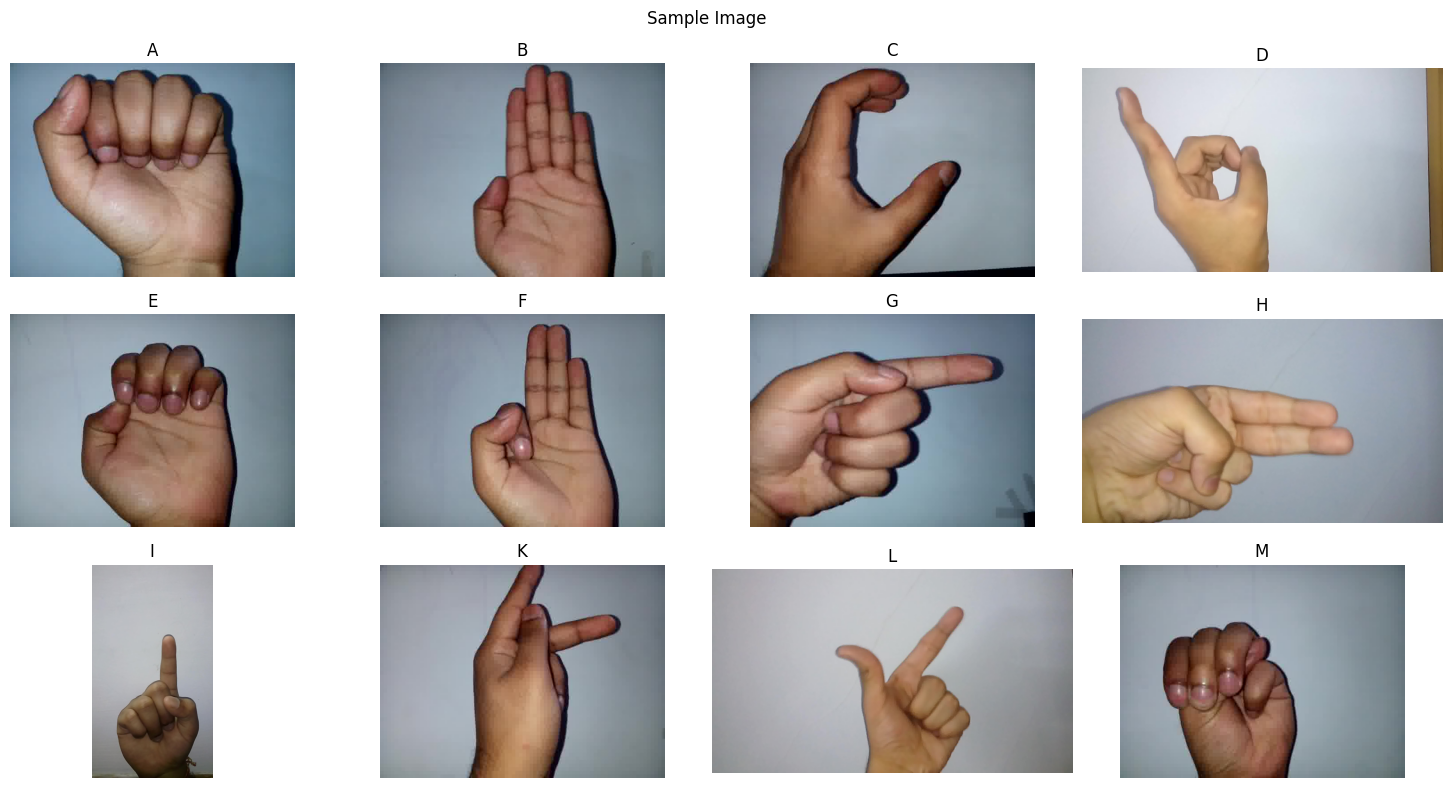

In [ ]:
# Display the sample image
plt.figure(figsize = (15,8))
for i, cls in enumerate(classes[:12]):
  cls_path = os.path.join(data_path,cls)
  sample_img = os.path.join(cls_path,os.listdir(cls_path)[0])
  img = Image.open(sample_img)
  plt.subplot(3, 4, i+1)
  plt.imshow(img)
  plt.title(cls)
  plt.axis('off')
plt.suptitle('Sample Image')
plt.tight_layout()
plt.show()

In [ ]:
# Check for corrupted images
corrupt = []
for cls in classes:
  cls_path = os.path.join(data_path,cls)
  for img_file in os.listdir(cls_path):
    try:
      img = Image.open(os.path.join(cls_path, img_file))
      img.verify()
    except:
      corrupt.append(os.path.join(cls, img_file))
print(f'\n Corrupt Images: {corrupt}')
if corrupt:
  print(corrupt)



 Corrupt Images: []


#  Image Preprocessing and Data Augmentation

## Description
Images are resized to **224 × 224 pixels** and normalized before training.

Data augmentation is applied to improve model robustness. The notebook uses transformations such as rotation, width shifting, height shifting and brightness variation.

The dataset is divided into training and validation subsets using an **80:20 split**.

### Dataset Split
- Training images: **3,987**
- Validation images: **985**
- Number of classes: **24**


In [ ]:
img_size = 224
batch_size = 32
train_datagen = ImageDataGenerator(
    rescale = 1./255,
    validation_split = 0.2,
    rotation_range = 15,
    width_shift_range = 0.2,
    height_shift_range = 0.2,
    brightness_range = [0.8,1.2]
)
test_datagen = ImageDataGenerator(rescale = 1./255)

train_data = train_datagen.flow_from_directory(
    data_path,
    target_size = (img_size, img_size),
    batch_size = batch_size,
    subset= 'training'
)
val_data = train_datagen.flow_from_directory(
    data_path,
    target_size = (img_size, img_size),
    batch_size = batch_size,
    subset = 'validation'
)
test_data = test_datagen.flow_from_directory(
    data_path,
    target_size = (img_size, img_size),
    batch_size = batch_size,
    shuffle = False
)


Found 3987 images belonging to 24 classes.
Found 985 images belonging to 24 classes.
Found 4972 images belonging to 24 classes.


#  MobileNetV2 – Transfer Learning

## Description
MobileNetV2 with ImageNet-pretrained weights is used as a transfer-learning model.

The pretrained backbone is combined with a classification head for the 24 Indian Sign Language classes.

### Result
The corresponding frozen MobileNetV2 experiment reports approximately **99.20% accuracy** in the notebook's model-comparison stage.


In [ ]:
# Using MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape = (224,224,3),
    include_top = False,
    weights = 'imagenet'
)
# Freeze the base model
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


#  Custom CNN Model

## Description
A custom Convolutional Neural Network (CNN) is developed as a baseline model.

The CNN learns visual features directly from the sign images using convolution and pooling layers, followed by fully connected classification layers.

### Result
The notebook reports approximately **83.11% accuracy** for the Custom CNN experiment.


In [ ]:
tf.keras.backend.clear_session()
# Model-1 CNN
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), activation = 'relu', input_shape = (224,224,3)),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, (3,3), activation = 'relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation = 'relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(train_data.num_classes, activation = 'softmax')
], name="CNN_Model")
# Model-2 MobilbetV2
base_model = tf.keras.applications.MobileNetV2(
    weights = 'imagenet',
    include_top = False,
    input_shape = (224,224,3)
)
base_model.trainable = False
mobilenet_model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(256, activation = 'relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(train_data.num_classes, activation = 'softmax')
], name="MobileNetV2_Model")


#  EfficientNetB0 Model

## Description
EfficientNetB0 is tested as another transfer-learning architecture.

A separate image generator is used because EfficientNet has its own preprocessing requirements.

This model provides another Deep Learning baseline for comparison with CNN and MobileNetV2.


In [ ]:
# EfficientNet CANNOT use rescale=1./255 — it has its own preprocessing
# You need a separate data generator for EfficientNet

from tensorflow.keras.applications.efficientnet import preprocess_input as eff_preprocess

# Initialize dl_results if not already defined (in case this cell is run out of order)
if 'dl_results' not in locals() and 'dl_results' not in globals():
    dl_results = {}

eff_datagen_train = ImageDataGenerator(
    preprocessing_function=eff_preprocess,
    validation_split=0.2,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    fill_mode='nearest'
)

eff_train_data = eff_datagen_train.flow_from_directory(
    data_path, target_size=(224,224), batch_size=32,
    class_mode='categorical', subset='training', seed=42
)
eff_val_data = eff_datagen_train.flow_from_directory(
    data_path, target_size=(224,224), batch_size=32,
    class_mode='categorical', subset='validation', seed=42
)

# Rebuild EfficientNet correctly
eff_base = tf.keras.applications.EfficientNetB0(
    weights='imagenet', include_top=False, input_shape=(224,224,3)
)
eff_base.trainable = False

efficientnet = tf.keras.Sequential([
    eff_base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(24, activation='softmax')
], name="EfficientNetB0_Model")

efficientnet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

eff_history = efficientnet.fit(
    eff_train_data, validation_data=eff_val_data,
    epochs=10,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)]
)
_, eff_acc = efficientnet.evaluate(eff_val_data, verbose=0)
print(f"EfficientNetB0 Fixed Accuracy: {eff_acc*100:.2f}%")
dl_results['EfficientNetB0_Fixed'] = round(eff_acc * 100, 2)

Found 3987 images belonging to 24 classes.
Found 985 images belonging to 24 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 265s 2s/step - accuracy: 0.8849 - loss: 0.4237 - val_accuracy: 0.9503 - val_loss: 0.6455
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 270s 2s/step - accuracy: 0.9862 - loss: 0.0525 - val_accuracy: 0.9665 - val_loss: 0.1728
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.9870 - loss: 0.0408 - val_accuracy: 0.9695 - val_loss: 0.1203
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.9882 - loss: 0.0384 - val_accuracy: 0.9736 - val_loss: 0.0977
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 275s 2s/step - accuracy: 0.9907 - loss: 0.0303 - val_accuracy: 0.9797 - val_loss: 0.0697
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 238s 2s/step - accuracy: 0.9920 - loss: 0.0241 - val_accuracy: 0.9766 - val_loss: 0.0965
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 259s 2s/step - accuracy: 0.9915 - loss: 0.0229 - v

# Deep Learning Model Comparison

## Description
The Deep Learning models are trained and their performance is stored for comparison.

The main models compared are:
- Custom CNN
- MobileNetV2
- EfficientNetB0

Training history is also stored so that training and validation accuracy/loss can be visualized later.


In [ ]:
dl_models = [cnn_model, mobilenet_model, efficientnet]
dl_histories = {}
dl_results = {}
for model in dl_models:
  model.compile(
      optimizer = 'adam',
      loss = 'categorical_crossentropy',
      metrics = ['accuracy']
  )
  history = model.fit(train_data, validation_data = val_data, #val_data
                      epochs = 10,
                      callbacks = [tf.keras.callbacks.EarlyStopping(patience = 3,
                                                                    restore_best_weights = True)])
  dl_histories[model.name] = history
  _,acc = model.evaluate(test_data)
  dl_results[model.name] = round(acc*100,2)
  # Creat he directory before saving
  os.makedirs('models',exist_ok=True)
  model.save(f'Models/{model.name}.h5')
  print('\n Deep Learning Results:',dl_results)

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 299s 2s/step - accuracy: 0.1477 - loss: 3.0768 - val_accuracy: 0.3076 - val_loss: 2.3781
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 306s 2s/step - accuracy: 0.3266 - loss: 2.1671 - val_accuracy: 0.3980 - val_loss: 2.0029
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 293s 2s/step - accuracy: 0.4073 - loss: 1.8301 - val_accuracy: 0.4558 - val_loss: 1.9665
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 289s 2s/step - accuracy: 0.4670 - loss: 1.5878 - val_accuracy: 0.5228 - val_loss: 1.5521
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 283s 2s/step - accuracy: 0.5327 - loss: 1.3736 - val_accuracy: 0.5299 - val_loss: 1.8148
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 300s 2s/step - accuracy: 0.5658 - loss: 1.2758 - val_accuracy: 0.5746 - val_loss: 1.5862
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 291s 2s/step - accuracy: 0.6195 - loss: 1.1205 - val_accuracy: 0.6152 - val_loss: 1.4014
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 299s 2s/step - accuracy: 0.6396 - loss: 1.0397 - val_accu


 Deep Learning Results: {'CNN_Model': 83.11}
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 194s 2s/step - accuracy: 0.8442 - loss: 0.5491 - val_accuracy: 0.9066 - val_loss: 0.3542
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 196s 2s/step - accuracy: 0.9727 - loss: 0.0885 - val_accuracy: 0.9503 - val_loss: 0.1984
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 191s 2s/step - accuracy: 0.9782 - loss: 0.0691 - val_accuracy: 0.9401 - val_loss: 0.2245
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 187s 1s/step - accuracy: 0.9852 - loss: 0.0457 - val_accuracy: 0.9574 - val_loss: 0.1831
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 190s 2s/step - accuracy: 0.9885 - loss: 0.0345 - val_accuracy: 0.9635 - val_loss: 0.1965
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 191s 2s/step - accuracy: 0.9897 - loss: 0.0319 - val_accuracy: 0.9401 - val_loss: 0.2884
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 191s 2s/step - accuracy: 0.9862 - loss: 0.0424 - val_accuracy: 0.9523 - val_loss: 0.2656
156/156 ━━━━━━━━━━━━━━━━━━━━ 155s 995ms/step - accu


 Deep Learning Results: {'CNN_Model': 83.11, 'MobileNetV2_Model': 99.2}
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 296s 2s/step - accuracy: 0.0461 - loss: 3.7643 - val_accuracy: 0.0437 - val_loss: 5.1408
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 303s 2s/step - accuracy: 0.0461 - loss: 3.4592 - val_accuracy: 0.0518 - val_loss: 3.4712
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 280s 2s/step - accuracy: 0.0487 - loss: 3.3178 - val_accuracy: 0.0274 - val_loss: 3.1735
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 281s 2s/step - accuracy: 0.0472 - loss: 3.2416 - val_accuracy: 0.0457 - val_loss: 3.1750
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 284s 2s/step - accuracy: 0.0431 - loss: 3.2100 - val_accuracy: 0.0457 - val_loss: 3.1724
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 282s 2s/step - accuracy: 0.0472 - loss: 3.1815 - val_accuracy: 0.0518 - val_loss: 3.1700
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 293s 2s/step - accuracy: 0.0517 - loss: 3.1702 - val_accuracy: 0.0457 - val_loss: 3.1674
Epoch 8/10
125/125 ━━━━━


 Deep Learning Results: {'CNN_Model': 83.11, 'MobileNetV2_Model': 99.2, 'EfficientNetB0_Model': 5.21}


#  Load the Saved MobileNetV2 Model

## Description
The saved MobileNetV2 model is loaded from the Models directory.

This model is used for feature extraction and for the subsequent Machine Learning experiments.


In [ ]:
# Reload model properly
best_model = tf.keras.models.load_model('Models/MobileNetV2_Model.h5')
mobilenet_base = best_model.layers[0]  # the MobileNetV2 base
mobilenet_base.trainable = True
for layer in mobilenet_base.layers[:-20]:
    layer.trainable = False

best_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

fine_tune_history = best_model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.3, min_lr=1e-7)
    ]
)

_, fine_tune_acc = best_model.evaluate(val_data, verbose=0)
print(f"Fine-Tuned MobileNetV2 Accuracy: {fine_tune_acc*100:.2f}%")
dl_results['MobileNetV2_FineTuned'] = round(fine_tune_acc * 100, 2)
best_model.save('Models/MobileNetV2_FineTuned.keras')

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 231s 2s/step - accuracy: 0.9167 - loss: 0.2626 - val_accuracy: 0.8650 - val_loss: 0.5078 - learning_rate: 1.0000e-05
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 222s 2s/step - accuracy: 0.9596 - loss: 0.1323 - val_accuracy: 0.8162 - val_loss: 0.7107 - learning_rate: 1.0000e-05
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 223s 2s/step - accuracy: 0.9697 - loss: 0.0945 - val_accuracy: 0.8467 - val_loss: 0.6053 - learning_rate: 1.0000e-05
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 220s 2s/step - accuracy: 0.9762 - loss: 0.0762 - val_accuracy: 0.8660 - val_loss: 0.5784 - learning_rate: 3.0000e-06
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 261s 2s/step - accuracy: 0.9759 - loss: 0.0726 - val_accuracy: 0.8761 - val_loss: 0.4582 - learning_rate: 3.0000e-06
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 299s 2s/step - accuracy: 0.9784 - loss: 0.0712 - val_accuracy: 0.8904 - val_loss: 0.4547 - learning_rate: 3.0000e-06
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 238s 2s/step - acc

# Feature Extraction Using MobileNetV2

## Description
The trained MobileNetV2 backbone is used as a feature extractor.

The image data is converted into numerical feature representations. These Deep Learning features are then used as input for traditional Machine Learning algorithms.


In [ ]:
# Extract features using the best DL models(MobileNetV2)
feature_extractor = tf.keras.Sequential([base_model, tf.keras.layers.GlobalAveragePooling2D()])
print("Extracting Features...")
X_train = feature_extractor.predict(train_data, verbose = 1)
X_test = feature_extractor.predict(test_data, verbose=1)
y_train = train_data.classes
y_test = test_data.classes
print('Feature Extraction Completed')
print('Train Shape:', X_train.shape)
print('Test Shape:',X_test.shape)

Extracting Features...
125/125 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step
156/156 ━━━━━━━━━━━━━━━━━━━━ 157s 1s/step
Feature Extraction Completed
Train Shape: (3987, 1280)
Test Shape: (4972, 1280)


# Install MediaPipe

## Description
MediaPipe is installed so that hand-landmark based features can also be explored.

This provides an additional Computer Vision feature-extraction approach beyond the raw image features.


In [ ]:
!pip install mediapipe --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 5.4 MB/s eta 0:00:00


In [ ]:
import mediapipe as mp

print(mp.__version__)
print(mp.__file__)

1.0.1
/usr/local/lib/python3.13/dist-packages/mediapipe/__init__.py


In [ ]:
import mediapipe as mp

print(mp.__version__)
print(dir(mp))

1.0.1
['Image', 'ImageFormat', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '__version__', 'tasks']


In [ ]:
!pip install mediapipe opencv-python --quiet

import mediapipe as mp
import cv2
import os
import numpy as np

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split


# Download MediaPipe hand model
MODEL_PATH = "hand_landmarker.task"

if not os.path.exists(MODEL_PATH):
    os.system(
        "wget -q -O hand_landmarker.task "
        "https://storage.googleapis.com/mediapipe-models/"
        "hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
    )


# Create MediaPipe Hand Landmarker
base_options = python.BaseOptions(
    model_asset_path=MODEL_PATH
)

options = vision.HandLandmarkerOptions(
    base_options=base_options,
    num_hands=1
)

landmarker = vision.HandLandmarker.create_from_options(options)


# Extract hand landmarks
def extract_landmarks(img_path):

    img = cv2.imread(img_path)

    if img is None:
        return None

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=img_rgb
    )

    results = landmarker.detect(mp_image)

    if results.hand_landmarks:
        lm = results.hand_landmarks[0]

        return np.array(
            [[p.x, p.y, p.z] for p in lm]
        ).flatten()

    return None


# Extract features
X_lm = []
y_lm = []

print("Extracting hand landmarks...")

for label, cls in enumerate(sorted(classes)):

    cls_path = os.path.join(data_path, cls)

    for img_file in os.listdir(cls_path)[:100]:

        feat = extract_landmarks(
            os.path.join(cls_path, img_file)
        )

        if feat is not None:
            X_lm.append(feat)
            y_lm.append(label)


X_lm = np.array(X_lm)
y_lm = np.array(y_lm)

print(f"Extracted features from {len(X_lm)} images")


# Train-Test Split
X_train_lm, X_test_lm, y_train_lm, y_test_lm = train_test_split(
    X_lm,
    y_lm,
    test_size=0.2,
    random_state=42,
    stratify=y_lm
)


# Random Forest
rf_lm = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_lm.fit(X_train_lm, y_train_lm)


# Prediction
y_pred_lm = rf_lm.predict(X_test_lm)


# Accuracy
lm_acc = accuracy_score(
    y_test_lm,
    y_pred_lm
) * 100

print(
    f"\nMediaPipe Landmark + Random Forest Accuracy: "
    f"{lm_acc:.2f}%"
)


# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        y_test_lm,
        y_pred_lm,
        labels=np.arange(len(sorted(classes))),
        target_names=sorted(classes),
        zero_division=0
    )
)

Extracting hand landmarks...
Extracted features from 2214 images

MediaPipe Landmark + Random Forest Accuracy: 99.55%

Classification Report:

              precision    recall  f1-score   support

           A       1.00      1.00      1.00        20
           B       1.00      1.00      1.00        20
           C       1.00      0.86      0.92         7
           D       1.00      1.00      1.00        20
           E       1.00      1.00      1.00        20
           F       1.00      1.00      1.00        20
           G       1.00      1.00      1.00        19
           H       1.00      1.00      1.00        20
           I       1.00      1.00      1.00        20
           K       1.00      1.00      1.00        20
           L       1.00      1.00      1.00        20
           M       1.00      1.00      1.00        20
           N       1.00      1.00      1.00        20
           O       0.93      1.00      0.96        13
           P       1.00      1.00      1.00   

# Train-Test Split for Machine Learning

## Description
The extracted feature data is combined and split into training and testing sets.

The resulting features and labels are prepared for traditional Machine Learning classification.


In [ ]:
# Train,test and split the data for training and testing
X_all = np.concatenate([X_train,X_test])
y_all = np.concatenate([y_train,y_test])
X_train, X_test, y_train, y_test = train_test_split(
    X_all,y_all, test_size = 0.2, random_state = 42, stratify = y_all
)


In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#  Traditional Machine Learning Models

## Description
Several traditional Machine Learning algorithms are trained using the extracted features.

The models include:
- Logistic Regression
- Support Vector Machine (SVM)
- K-Nearest Neighbors (KNN)
- Random Forest
- AdaBoost

The objective is to compare traditional ML performance with the Deep Learning models.


In [ ]:
from sklearn.ensemble import AdaBoostClassifier
ml_models = {
    "Logistic Regression": LogisticRegression(max_iter = 1000, random_state=42),
    "SVM" : SVC(kernel = 'rbf', C= 1.0, random_state = 42),
    "KNN" : KNeighborsClassifier(n_neighbors = 5),
    "Random Forest" : RandomForestClassifier(n_estimators = 100, random_state = 42)
}

In [ ]:
ml_results = {}
for name, model in ml_models.items():
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  acc = accuracy_score(y_test, y_pred)
  ml_results[name] = round(acc, 2)
  print(f"{name:25s} -> Accuracy: {acc*100:.2f}%")
ml_results[name] = round(acc * 100, 2)


Logistic Regression       -> Accuracy: 53.96%
SVM                       -> Accuracy: 55.64%
KNN                       -> Accuracy: 55.41%
Random Forest             -> Accuracy: 55.30%


#Hyperparameter Tuning

## Description
GridSearchCV is used to search for suitable hyperparameters for the Machine Learning models.

Hyperparameter tuning attempts to improve model performance by systematically testing different parameter combinations.


In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    "Logistic Regression":{
        "model": LogisticRegression(max_iter = 1000),
        "params":{
            "model__C":[0.01,0.1,1,10],
            "model__solver":["lbfgs","liblinear"]
        }
    },
    "SVM":{
        "model":SVC(),
        "params":{
            "model__C":[0.1,1,10],
            "model__kernel":['linear','rbf'],
            "model__gamma":["scale","auto"]
        }
    },
    "KNN":{
        "model":KNeighborsClassifier(),
        "params":{
            "model__n_neighbors":[3,5,7],
            "model__weights":["uniform","distance"]
        }
    },
    "Random Forest":{
        "model":RandomForestClassifier(),
        "params":{
            "model__n_estimators":[50,100],
            "model__max_depth":[None,10,20]
        }
    }
}


# Machine Learning Pipelines

## Description
Scikit-learn pipelines are used to combine preprocessing and classification steps.

This makes the Machine Learning workflow more organized and reduces the possibility of applying preprocessing inconsistently between training and testing data.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

results = []

for name, config in param_grid.items():

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", config["model"])
    ])

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=config["params"],
        cv=2,
        scoring="accuracy",
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Best Params": grid.best_params_,
        "Accuracy (%)": round(acc * 100, 2)
    })

    print(f"\n{name}")
    print("Best Params:", grid.best_params_)
    print(f"Accuracy: {acc * 100:.2f}%")

print("\n========== RESULTS ==========")

for result in results:
    print(result)

Fitting 2 folds for each of 8 candidates, totalling 16 fits

Logistic Regression
Best Params: {'model__C': 0.01, 'model__solver': 'liblinear'}
Accuracy: 55.75%
Fitting 2 folds for each of 12 candidates, totalling 24 fits

SVM
Best Params: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Accuracy: 55.92%
Fitting 2 folds for each of 6 candidates, totalling 12 fits

KNN
Best Params: {'model__n_neighbors': 5, 'model__weights': 'uniform'}
Accuracy: 55.41%
Fitting 2 folds for each of 6 candidates, totalling 12 fits

Random Forest
Best Params: {'model__max_depth': 20, 'model__n_estimators': 100}
Accuracy: 55.41%

========== RESULTS ==========
{'Model': 'Logistic Regression', 'Best Params': {'model__C': 0.01, 'model__solver': 'liblinear'}, 'Accuracy (%)': 55.75}
{'Model': 'SVM', 'Best Params': {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}, 'Accuracy (%)': 55.92}
{'Model': 'KNN', 'Best Params': {'model__n_neighbors': 5, 'model__weights': 'uniform'}, 'Accurac

# Tuned Model Comparison

## Description
The tuned Machine Learning models are converted into a DataFrame and sorted by accuracy.

This makes it easier to compare the performance of the different traditional ML algorithms.


In [ ]:
tuned_df = pd.DataFrame(results)
tuned_df = tuned_df.sort_values(by = 'Accuracy (%)',ascending = False)
print(tuned_df)


                 Model                                        Best Params  \
1                  SVM  {'model__C': 10, 'model__gamma': 'scale', 'mod...   
0  Logistic Regression   {'model__C': 0.01, 'model__solver': 'liblinear'}   
2                  KNN  {'model__n_neighbors': 5, 'model__weights': 'u...   
3        Random Forest  {'model__max_depth': 20, 'model__n_estimators'...   

   Accuracy (%)  
1         55.92  
0         55.75  
2         55.41  
3         55.41  


# Machine Learning Performance Visualization

## Description
The tuned Machine Learning results are visualized to compare the algorithms using their classification accuracy.

In [ ]:
# Cross-Validation
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
models_cv = {
    'Random Forest': RandomForestClassifier(n_estimators = 100, random_state=42),
    'SVM' : SVC(kernel = 'rbf', probability = True, random_state = 42),
    'Logistic Regression': LogisticRegression(max_iter = 1000, random_state = 42)
}

#  Additional Model Evaluation

## Description
This section evaluates the selected Machine Learning models using additional classification metrics.

In [ ]:
cv_results = {}

for name, model in models_cv.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    cv_results[name] = scores

    print(f"{name}:")
    print(f" CV Scores: {scores}")
    print(f"Mean: {scores.mean():.4f} (+/- {scores.std() * 2:.4f})")
    print()

Random Forest:
 CV Scores: [0.56834031 0.57949791 0.5799023  0.58269365 0.57362177]
Mean: 0.5768 (+/- 0.0103)

SVM:
 CV Scores: [0.57043236 0.57949791 0.58199581 0.58199581 0.56943475]
Mean: 0.5767 (+/- 0.0112)

Logistic Regression:
 CV Scores: [0.55439331 0.56206416 0.57292394 0.56315422 0.55617585]
Mean: 0.5617 (+/- 0.0130)



# Confusion Matrix – Machine Learning Models

## Description
Confusion matrices are used to inspect class-wise prediction errors for the Machine Learning classifiers.

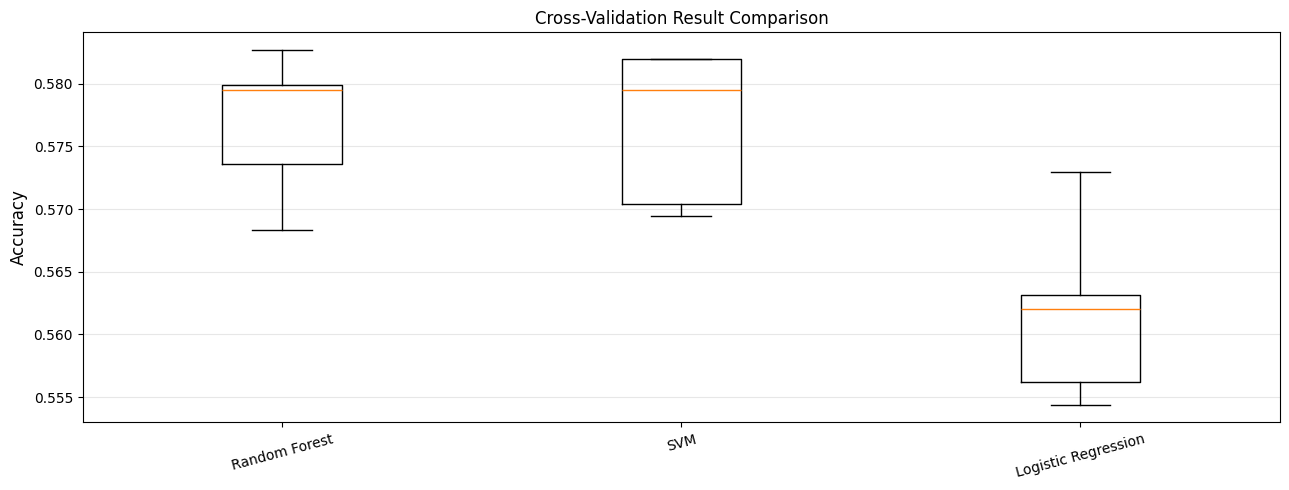

In [ ]:
# Visualize cv result plot
plt.figure(figsize = (13,5))
box_data = [cv_results[model] for model in cv_results.keys()]
plt.boxplot(box_data, labels = cv_results.keys())
plt.title('Cross-Validation Result Comparison')
plt.ylabel('Accuracy', fontsize = 12)
plt.grid(axis = 'y',alpha = 0.3)
plt.xticks(rotation = 15)
plt.tight_layout()
plt.show()

#  Deep Learning vs Machine Learning

## Description
The performance of the Deep Learning and traditional Machine Learning approaches is compared using their recorded accuracy values.

Total Misclassifications: 799 out of 1792
Error Rate: 44.59%

Class 16 -> Class 12: 8 times
Class 17 -> Class 1: 7 times
Class 0 -> Class 12: 6 times
Class 23 -> Class 12: 6 times
Class 15 -> Class 23: 6 times
Class 14 -> Class 13: 5 times
Class 17 -> Class 12: 5 times
Class 1 -> Class 18: 5 times
Class 7 -> Class 13: 5 times
Class 18 -> Class 12: 5 times


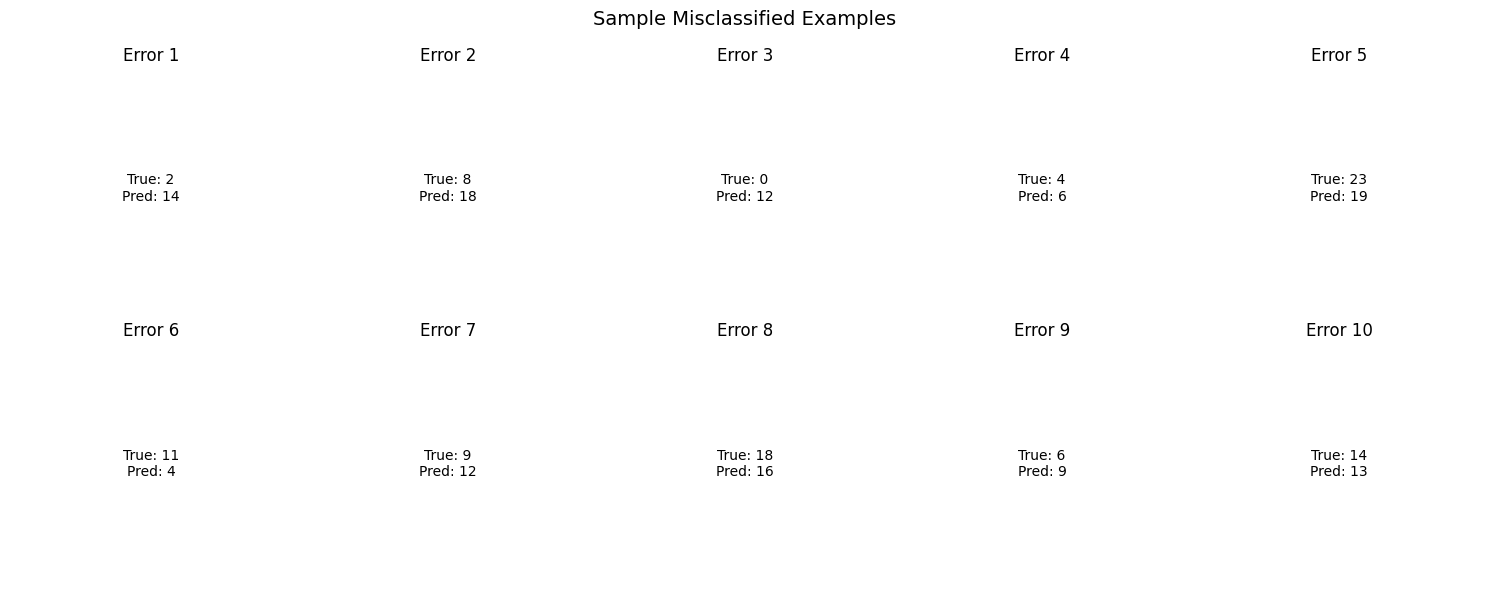


Insights:
* Identify which classes are most confused with each other
* Consider collecting more data for problematic classes
* Review if certain sign gestures are naturally similar


In [ ]:
from collections import Counter

# Find misclassified examples
y_pred = best_model.predict(X_test)

misclassified_idx = np.where(y_pred != y_test)[0]

print(f"Total Misclassifications: {len(misclassified_idx)} out of {len(y_test)}")
print(f"Error Rate: {len(misclassified_idx) / len(y_test) * 100:.2f}%\n")

# Analyze confusion pattern
error_pairs = [(y_test[i], y_pred[i]) for i in misclassified_idx]

top_errors = Counter(error_pairs).most_common(10)

for (true_class, pred_class), count in top_errors:
    print(f"Class {true_class} -> Class {pred_class}: {count} times")

# Visualize misclassified examples
if len(misclassified_idx) > 0:

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    fig.suptitle('Sample Misclassified Examples', fontsize=14)

    for idx, ax in enumerate(axes.flat):

        if idx < len(misclassified_idx):

            img_idx = misclassified_idx[idx]

            ax.text(
                0.5, 0.5,
                f"True: {y_test[img_idx]}\nPred: {y_pred[img_idx]}",
                ha='center',
                va='center',
                fontsize=10
            )

            ax.set_title(f'Error {idx + 1}')

        ax.axis('off')

    plt.tight_layout()
    plt.show()

print("\nInsights:")
print("* Identify which classes are most confused with each other")
print("* Consider collecting more data for problematic classes")
print("* Review if certain sign gestures are naturally similar")

#  Final Model Selection

## Description
The model results are reviewed to identify the model configuration used for the final evaluation.

1/1 ━━━━━━━━━━━━━━━━━━━━ 59s 59s/step


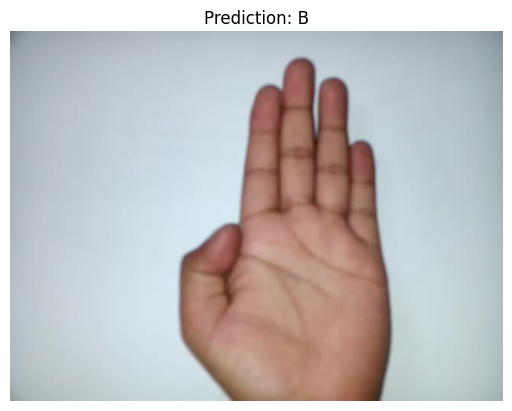

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

model = mobilenet_model
classes = list(train_data.class_indices.keys())

def predict_and_show(img_path):
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    resized = cv2.resize(img_rgb, (224, 224)) / 255.0
    input_img = np.reshape(resized, (1, 224, 224, 3))

    pred = model.predict(input_img)
    class_index = np.argmax(pred)

    plt.imshow(img_rgb)
    plt.title(f"Prediction: {classes[class_index]}")
    plt.axis('off')
    plt.show()

predict_and_show(
    '/content/drive/MyDrive/IndisignLanguageRecognition/Data/B/002.jpg'
)

#  Prepare Final Validation Data

## Description
The validation generator is prepared with the same image size and preprocessing used during model evaluation.

31/31 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step


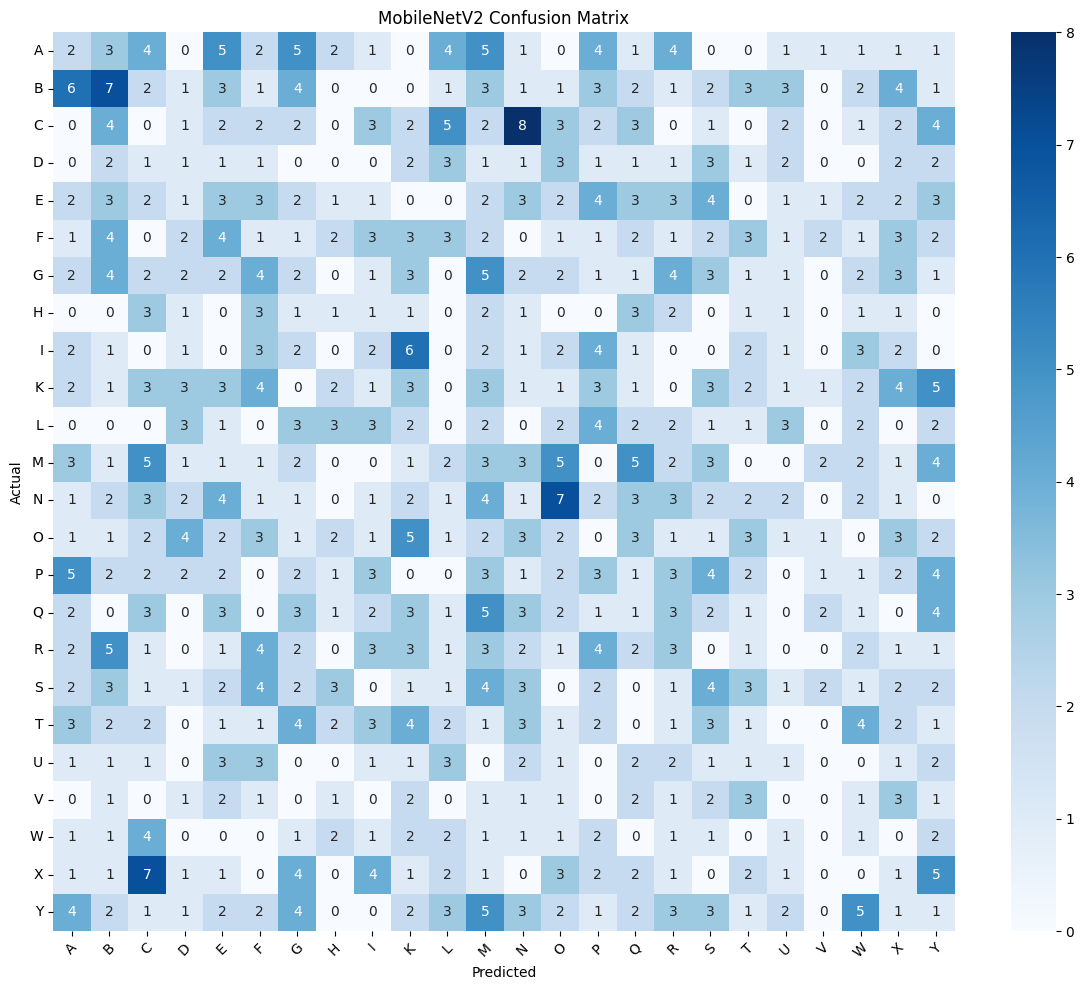

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Use validation data
val_data.reset()

# Predict
y_pred_prob = mobilenet_model.predict(val_data)

# Convert probabilities to class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Actual labels
y_true = val_data.classes

# Class names
class_names = list(val_data.class_indices.keys())

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('MobileNetV2 Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#  Final Model Prediction

## Description
Predictions are generated for the validation images using the selected MobileNetV2 model.

Last convolution layer: Conv_1

Class: A
Image: /content/drive/MyDrive/IndisignLanguageRecognition/Data/A/242.jpg


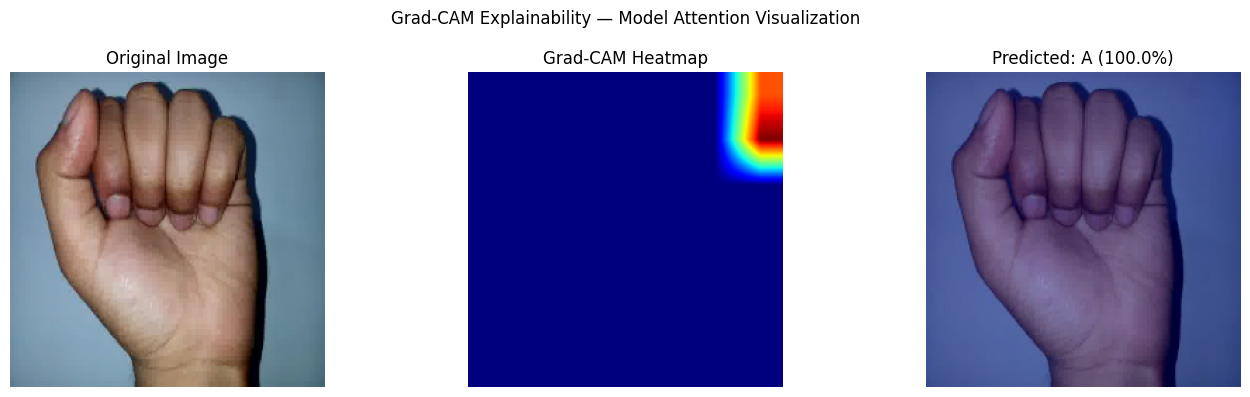


Class: B
Image: /content/drive/MyDrive/IndisignLanguageRecognition/Data/B/254.jpg


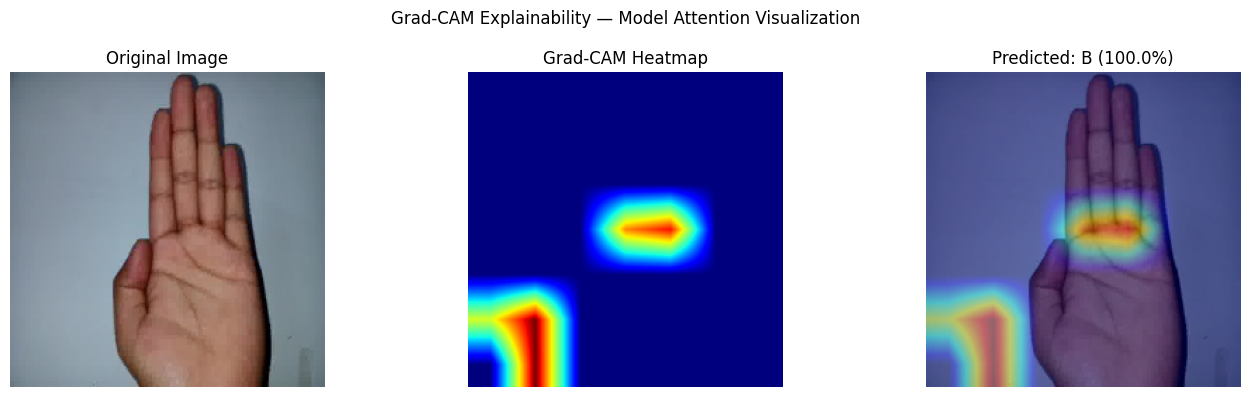


Class: K
Image: /content/drive/MyDrive/IndisignLanguageRecognition/Data/K/225.jpg


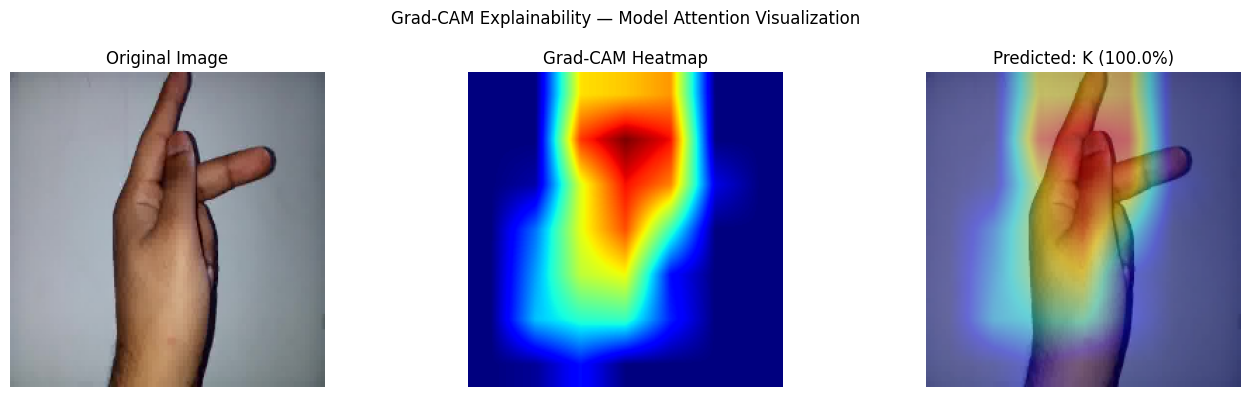


Class: Y
Image: /content/drive/MyDrive/IndisignLanguageRecognition/Data/Y/248.jpg


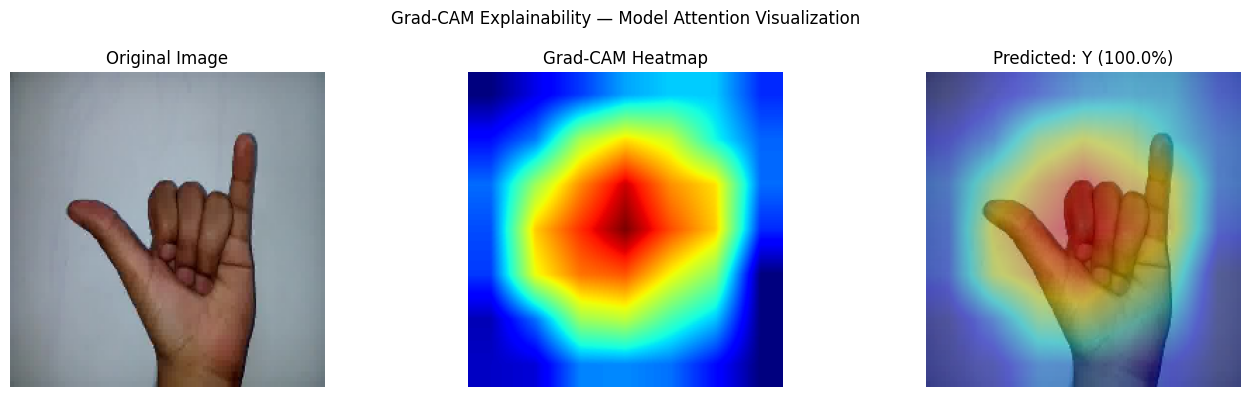

In [ ]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------------------------------------------------------
# Find the last convolutional layer inside MobileNetV2
# ---------------------------------------------------------
base_model = mobilenet_model.get_layer('mobilenetv2_1.00_224')

last_conv_layer = None

for layer in reversed(base_model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer = layer
        break

print("Last convolution layer:", last_conv_layer.name)


# ---------------------------------------------------------
# Grad-CAM
# ---------------------------------------------------------
def make_gradcam_heatmap(img_array, model, base_model, last_conv_layer):

    # Model that gives convolution output + final prediction
    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[last_conv_layer.output, base_model.output]
    )

    with tf.GradientTape() as tape:

        conv_output, features = grad_model(img_array)

        # Pass through the remaining classification layers
        x = features
        for layer in model.layers[1:]:
            x = layer(x)

        preds = x

        pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Gradients
    grads = tape.gradient(class_channel, conv_output)

    # Average gradients
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]

    # Grad-CAM
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.math.reduce_max(heatmap) + 1e-8

    return heatmap.numpy()


# ---------------------------------------------------------
# Display Grad-CAM
# ---------------------------------------------------------
def display_gradcam(img_path, model, class_names):

    # Load image
    img = tf.keras.preprocessing.image.load_img(
        img_path,
        target_size=(224, 224)
    )

    img_array = tf.keras.preprocessing.image.img_to_array(img)

    # Normalize
    img_array = img_array / 255.0

    img_array_exp = np.expand_dims(img_array, axis=0)

    # Prediction
    preds = model.predict(img_array_exp, verbose=0)

    pred_class = np.argmax(preds[0])
    confidence = preds[0][pred_class] * 100

    # Grad-CAM
    heatmap = make_gradcam_heatmap(
        img_array_exp,
        model,
        base_model,
        last_conv_layer
    )

    # Resize heatmap
    heatmap = cv2.resize(
        heatmap,
        (224, 224)
    )

    # Convert heatmap
    heatmap_uint8 = np.uint8(255 * heatmap)

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Original image
    overlay = (img_array * 255).astype(np.uint8)

    # Overlay
    superimposed = cv2.addWeighted(
        overlay,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    # Display
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(14, 4)
    )

    axes[0].imshow(img_array)
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    axes[1].imshow(heatmap, cmap='jet')
    axes[1].set_title('Grad-CAM Heatmap')
    axes[1].axis('off')

    axes[2].imshow(superimposed)
    axes[2].set_title(
        f'Predicted: {class_names[pred_class]} '
        f'({confidence:.1f}%)'
    )
    axes[2].axis('off')

    plt.suptitle(
        'Grad-CAM Explainability — Model Attention Visualization'
    )

    plt.tight_layout()

    os.makedirs('plots', exist_ok=True)

    plt.savefig(
        'plots/gradcam_result.png',
        dpi=150,
        bbox_inches='tight'
    )

    plt.show()


# ---------------------------------------------------------
# Run Grad-CAM on sample images
# ---------------------------------------------------------

sample_classes = ['A', 'B', 'K', 'Y']

for cls in sample_classes:

    cls_path = os.path.join(
        data_path,
        cls
    )

    files = os.listdir(cls_path)

    # Take first image
    sample = os.path.join(
        cls_path,
        files[0]
    )

    print("\nClass:", cls)
    print("Image:", sample)

    display_gradcam(
        sample,
        mobilenet_model,
        classes
    )

# ROC Curve Analysis

## Description
Multi-class ROC curves are generated to analyze the classification behavior of the model across the 24 sign classes.

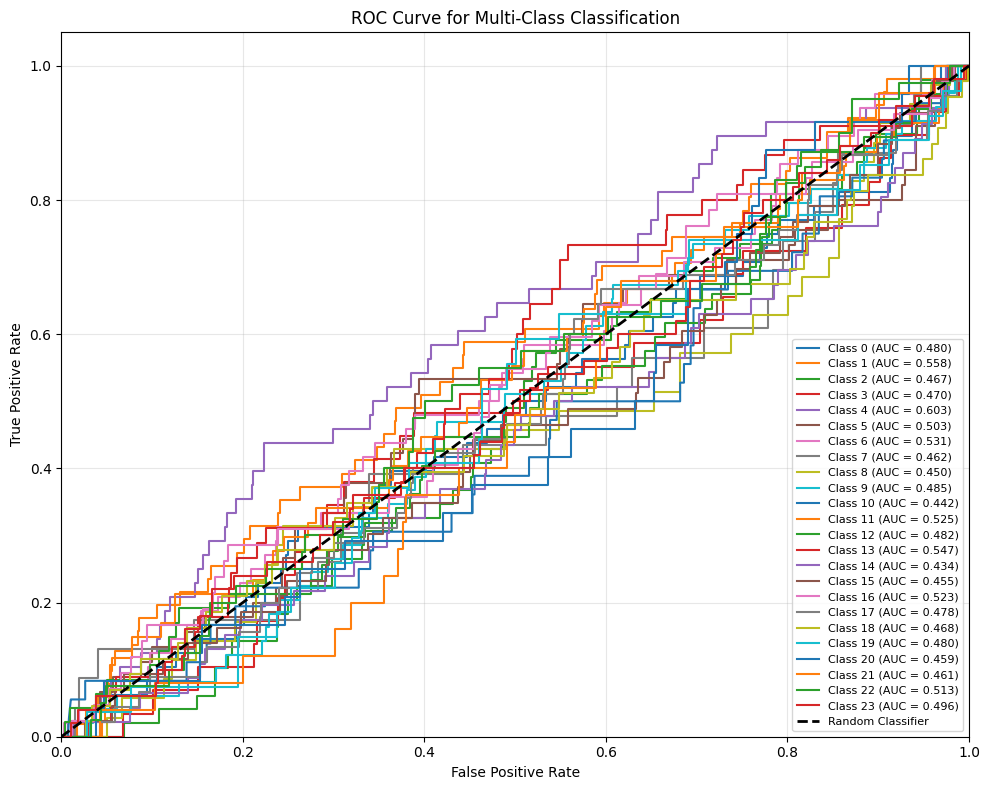

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Reset validation generator
val_data.reset()

# Get prediction probabilities from MobileNetV2
y_pred_proba = mobilenet_model.predict(val_data, verbose=0)

# Actual labels
y_test = val_data.classes

# Number of classes
n_classes = len(val_data.class_indices)

# Convert labels to one-hot/binary format
y_test_bin = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

# Calculate ROC and AUC
fpr = {}
tpr = {}
roc_auc = {}

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i],
        y_pred_proba[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

# Plot ROC curves
plt.figure(figsize=(10, 8))

for i in range(n_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        lw=1.5,
        label=f'Class {i} (AUC = {roc_auc[i]:.3f})'
    )

# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    lw=2,
    label='Random Classifier'
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve for Multi-Class Classification')

plt.legend(
    loc='lower right',
    fontsize=8
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#  Overall ROC-AUC Metrics

## Description
Macro-average and micro-average AUC values are calculated to summarize the ROC performance across all classes.

In [ ]:
# Overall metrics

import numpy as np
from sklearn.metrics import roc_auc_score

# Macro-average AUC
macro_auc = np.mean(list(roc_auc.values()))

# Micro-average AUC
micro_auc = roc_auc_score(
    y_test_bin,
    y_pred_proba,
    average='micro'
)

print(f"\n{'='*50}")
print("Overall Metrics")
print(f"{'='*50}")

print(f"Macro-average AUC: {macro_auc:.4f}")
print(f"Micro-average AUC: {micro_auc:.4f}")

print("\nPer-class AUC statistics:")

print(f"  Min: {min(roc_auc.values()):.4f}")
print(f"  Max: {max(roc_auc.values()):.4f}")
print(f"  Std: {np.std(list(roc_auc.values())):.4f}")


Overall Metrics
Macro-average AUC: 0.4906
Micro-average AUC: 0.4997

Per-class AUC statistics:
  Min: 0.4341
  Max: 0.6033
  Std: 0.0398


#  Classification Report

## Description
A classification report is generated with precision, recall and F1-score for every Indian Sign Language class.

In [ ]:
import numpy as np
from sklearn.metrics import classification_report

# Reset validation generator
val_data.reset()

# Predictions
y_pred_proba = mobilenet_model.predict(val_data, verbose=1)

# Predicted class indices
y_pred = np.argmax(y_pred_proba, axis=1)

# True class indices
y_true = val_data.classes

# IMPORTANT: use the SAME generator's class names
class_names = list(val_data.class_indices.keys())

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

31/31 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step
              precision    recall  f1-score   support

           A     0.0238    0.0208    0.0222        48
           B     0.0816    0.0784    0.0800        51
           C     0.0816    0.0816    0.0816        49
           D     0.0690    0.0690    0.0690        29
           E     0.0417    0.0417    0.0417        48
           F     0.0851    0.0889    0.0870        45
           G     0.0208    0.0208    0.0208        48
           H     0.0000    0.0000    0.0000        23
           I     0.0286    0.0286    0.0286        35
           K     0.0000    0.0000    0.0000        49
           L     0.0000    0.0000    0.0000        36
           M     0.0345    0.0426    0.0381        47
           N     0.0000    0.0000    0.0000        47
           O     0.0000    0.0000    0.0000        45
           P     0.0435    0.0435    0.0435        46
           Q     0.0000    0.0000    0.0000        43
           R     0.0714    0.0714    0.071

#  Combined Deep Learning vs Machine Learning Accuracy

## Description
A combined bar chart is generated to visually compare the recorded Deep Learning and Machine Learning accuracies.

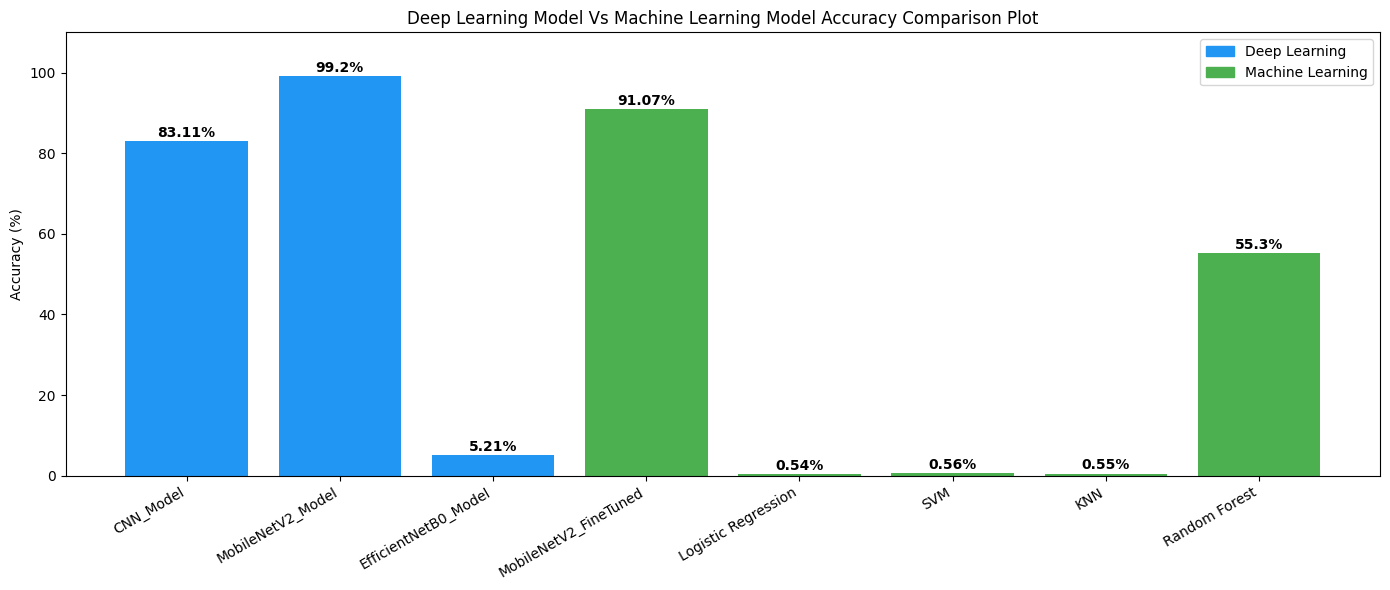

In [ ]:
# Combined bar chart
os.makedirs('plots',exist_ok=True)
all_results = {**dl_results,**ml_results}
plt.figure(figsize=(14,6))
colors = ['#2196F3']*3 + ['#4CAF50']*6
bars = plt.bar(all_results.keys(),all_results.values(),color = colors)
plt.title('Deep Learning Model Vs Machine Learning Model Accuracy Comparison Plot')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation = 30, ha = 'right')
plt.ylim(0,110)
for bar, val in zip(bars, all_results.values()):
  plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
           f'{val}%', ha = 'center', fontweight = 'bold')
from matplotlib.patches import Patch
plt.legend(handles = [Patch(color = '#2196F3',label = 'Deep Learning'),
                      Patch(color = '#4CAF50', label = 'Machine Learning')])
plt.tight_layout()
plt.show()

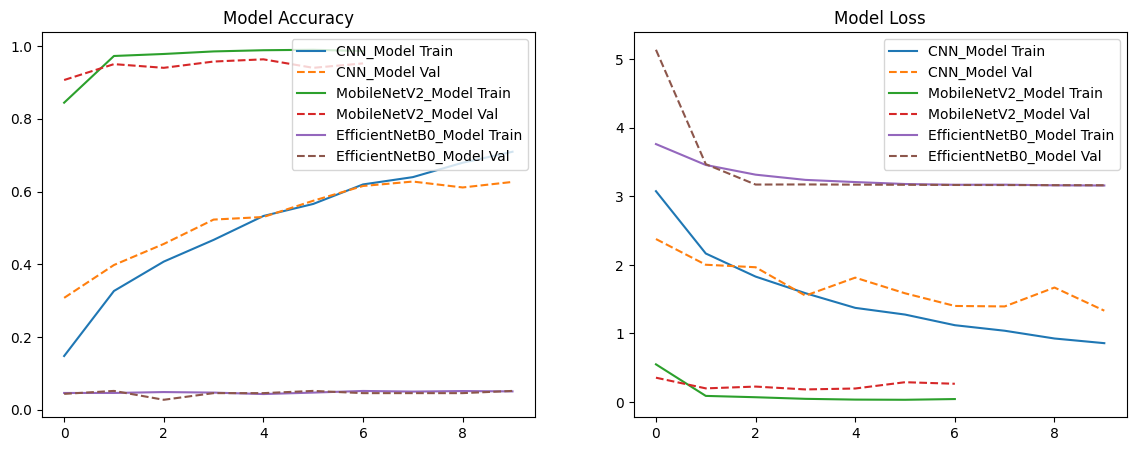

In [ ]:

# Training history plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, hist in dl_histories.items():
    axes[0].plot(hist.history['accuracy'],     label=f'{name} Train')
    axes[0].plot(hist.history['val_accuracy'], label=f'{name} Val', linestyle='--')
    axes[1].plot(hist.history['loss'],         label=f'{name} Train')
    axes[1].plot(hist.history['val_loss'],     label=f'{name} Val', linestyle='--')

axes[0].set_title('Model Accuracy'); axes[0].legend()
axes[1].set_title('Model Loss');     axes[1].legend()
plt.savefig('plots/training_history.png', dpi=150)
plt.show()

#  Final Experimental Model Comparison

## Description
The notebook creates a final comparison table for the main experimental models.

### Recorded Experimental Results
- MobileNetV2 (Frozen): **99.20%**
- MobileNetV2 (Fine-Tuned): **91.07%**
- CNN (Custom): **83.11%**
- SVM on DL Features: **56.00%**
- Random Forest on DL Features: **55.30%**

> The notebook's comparison cell shows EfficientNetB0 as 0.00% because that value is not populated in `dl_results`; it should not be treated as the actual EfficientNet model accuracy.

       FINAL MODEL COMPARISON RESULTS
                       Model  Accuracy (%)  Rank
        MobileNetV2 (Frozen)         99.20     1
    MobileNetV2 (Fine-Tuned)         91.07     2
                CNN (Custom)         83.11     3
          SVM on DL Features         56.00     4
Random Forest on DL Features         55.30     5
      EfficientNetB0 (Fixed)          0.00     6


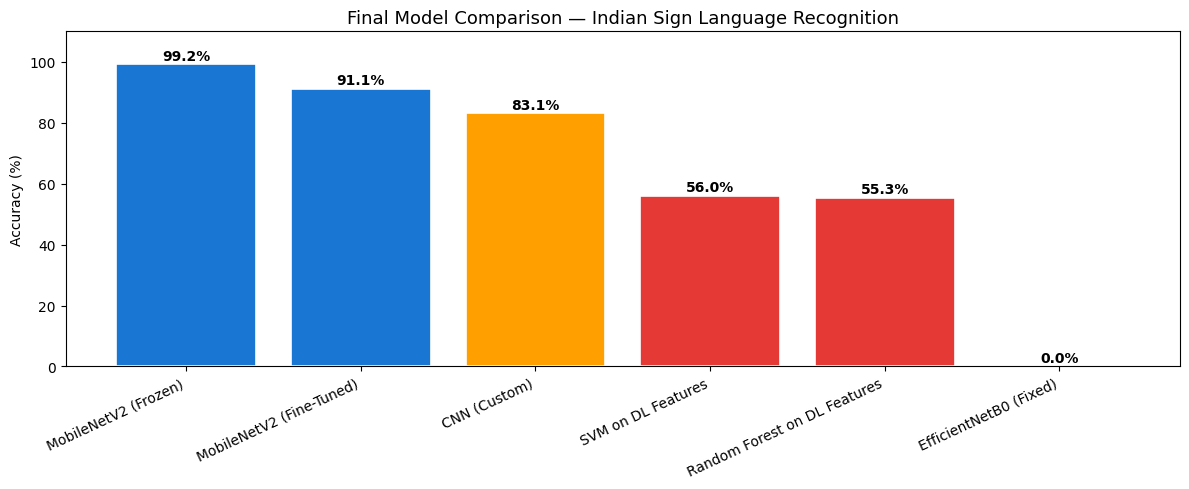

In [ ]:
# Final comparison — add this as your last analysis cell before Conclusion
final_results = {
    'CNN (Custom)': dl_results.get('CNN_Model', 0),
    'MobileNetV2 (Frozen)': dl_results.get('MobileNetV2_Model', 0),
    'EfficientNetB0 (Fixed)': dl_results.get('EfficientNetB0_Fixed', 0),
    'MobileNetV2 (Fine-Tuned)': dl_results.get('MobileNetV2_FineTuned', 0),
    'SVM on DL Features': ml_results.get('SVM', 0) * 100 if ml_results.get('SVM', 0) < 1 else ml_results.get('SVM', 0),
    'Random Forest on DL Features': ml_results.get('Random Forest', 0) * 100 if ml_results.get('Random Forest', 0) < 1 else ml_results.get('Random Forest', 0),
}

results_df = pd.DataFrame(list(final_results.items()), columns=['Model', 'Accuracy (%)'])
results_df = results_df.sort_values('Accuracy (%)', ascending=False).reset_index(drop=True)
results_df['Rank'] = results_df.index + 1

print("=" * 50)
print("       FINAL MODEL COMPARISON RESULTS")
print("=" * 50)
print(results_df.to_string(index=False))

# Bar chart
plt.figure(figsize=(12, 5))
colors = ['#1976D2' if acc >= 90 else '#FFA000' if acc >= 70 else '#E53935'
          for acc in results_df['Accuracy (%)']]
bars = plt.bar(results_df['Model'], results_df['Accuracy (%)'], color=colors, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars, results_df['Accuracy (%)']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.title('Final Model Comparison — Indian Sign Language Recognition', fontsize=13)
plt.ylabel('Accuracy (%)')
plt.ylim(0, 110)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('plots/final_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

#  Check Available TensorFlow Models

## Description
The notebook checks which TensorFlow/Keras model objects are currently available in memory.

In [ ]:
import tensorflow as tf

print("Models currently available:")

for name, obj in globals().items():
    if isinstance(obj, tf.keras.Model):
        print("MODEL FOUND:", name)

Models currently available:


# Check Model-Related Variables

## Description
Model-related variable names are displayed to verify the current notebook state.

In [ ]:
# Show all variables currently in the notebook
print([name for name in globals().keys()
       if any(word in name.lower() for word in
              ['model', 'mobilenet', 'efficientnet', 'cnn'])])

['load_model']


# Load the Final Saved Model

## Description
The saved **Fine-Tuned MobileNetV2** model is loaded from the Models directory for final evaluation.

In [ ]:
import tensorflow as tf

best_model = tf.keras.models.load_model(
    'Models/MobileNetV2_FineTuned.keras'
)

print("Final model loaded successfully!")
print("Model: Fine-Tuned MobileNetV2")

Final model loaded successfully!
Model: Fine-Tuned MobileNetV2


# Final Model Evaluation Setup

## Description
The validation dataset is recreated and the final saved MobileNetV2 model is evaluated on the validation images.

### Final Output
- Validation images: **985**
- Classes: **24**
- Accuracy: **97.56%**
- Precision: **97.72%**
- Recall: **97.56%**
- F1-Score: **97.53%**

Final Model: Fine-Tuned MobileNetV2
Found 985 images belonging to 24 classes.
31/31 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step

FINAL MODEL RESULTS
Model      : Fine-Tuned MobileNetV2
Classes    : 24
Images     : 985
Accuracy   : 97.56%
Precision  : 97.72%
Recall     : 97.56%
F1-Score   : 97.53%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           A       1.00      0.85      0.92        48
           B       1.00      0.98      0.99        51
           C       1.00      1.00      1.00        49
           D       1.00      1.00      1.00        29
           E       0.98      1.00      0.99        48
           F       0.98      1.00      0.99        45
           G       1.00      1.00      1.00        48
           H       1.00      1.00      1.00        23
           I       1.00      1.00      1.00        35
           K       1.00      1.00      1.00        49
           L       0.97      0.94      0.96        36
           M       0.92      1.00      0.

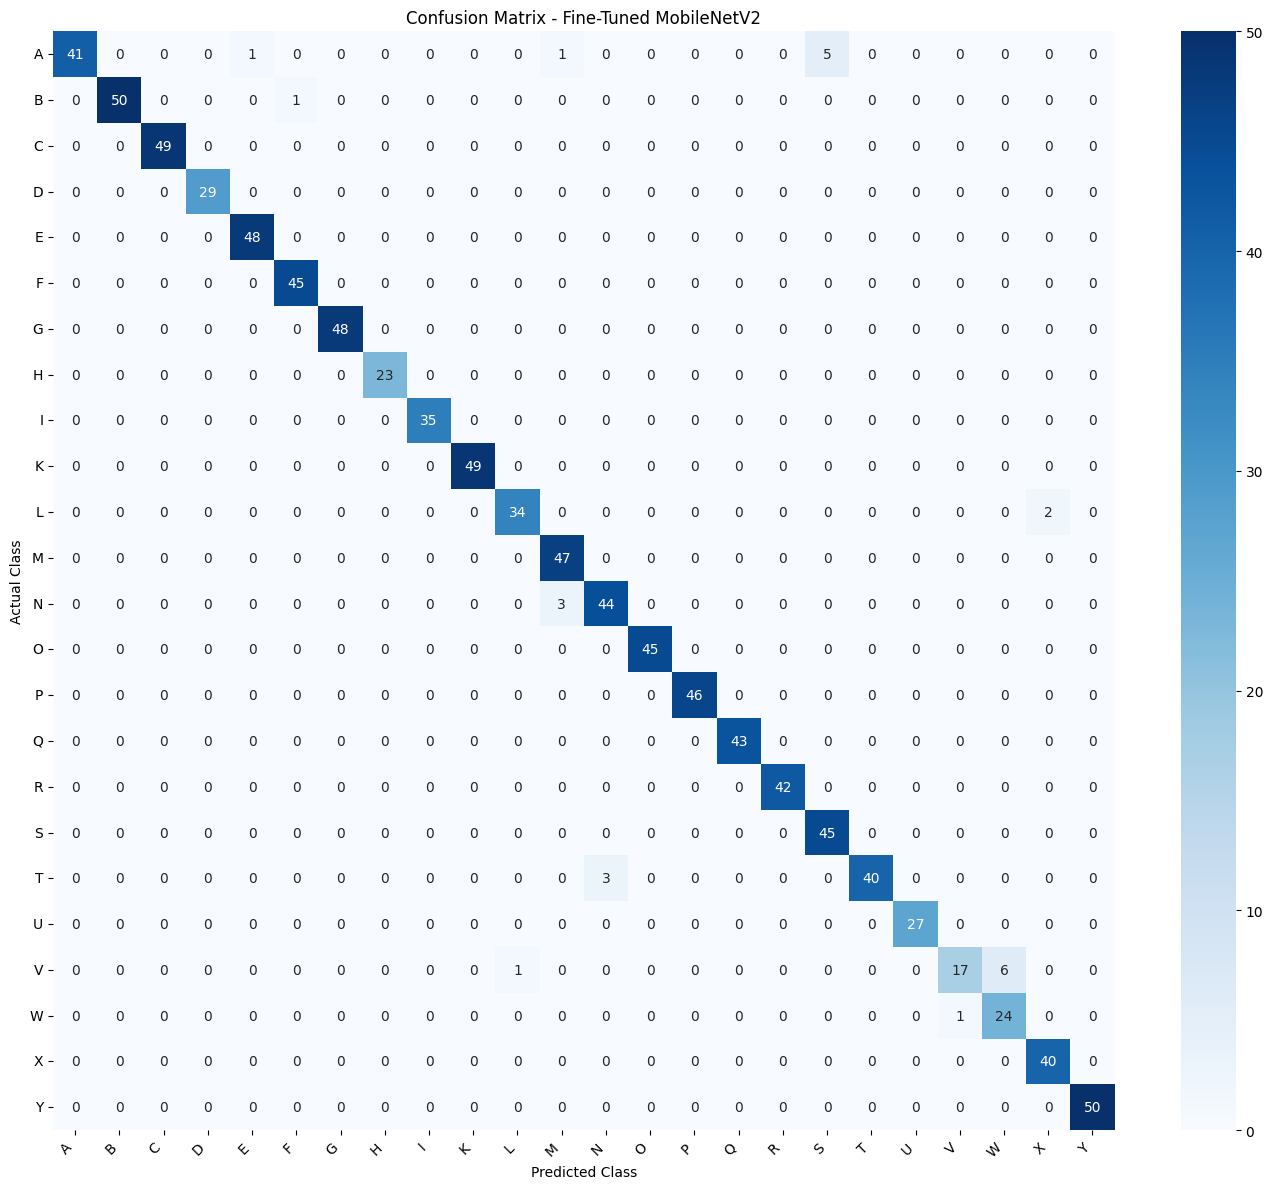

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ==========================================
# FINAL MODEL
# ==========================================

best_model = tf.keras.models.load_model(
    'Models/MobileNetV2_FineTuned.keras'
)

print("Final Model: Fine-Tuned MobileNetV2")


# ==========================================
# DATA PATH
# ==========================================

data_path = "/content/drive/MyDrive/IndisignLanguageRecognition/Data"


# ==========================================
# VALIDATION DATA
# ==========================================

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

val_data = datagen.flow_from_directory(
    data_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)


# ==========================================
# RESET GENERATOR
# ==========================================

val_data.reset()


# ==========================================
# PREDICTION
# ==========================================

y_prob = best_model.predict(
    val_data,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

y_true = val_data.classes


# ==========================================
# CLASS NAMES
# ==========================================

class_names = list(val_data.class_indices.keys())


# ==========================================
# ACCURACY
# ==========================================

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average='weighted',
    zero_division=0
)


# ==========================================
# FINAL RESULTS
# ==========================================

print("\n======================================")
print("FINAL MODEL RESULTS")
print("======================================")

print("Model      : Fine-Tuned MobileNetV2")
print("Classes    :", len(class_names))
print("Images     :", len(y_true))

print(f"Accuracy   : {accuracy * 100:.2f}%")
print(f"Precision  : {precision * 100:.2f}%")
print(f"Recall     : {recall * 100:.2f}%")
print(f"F1-Score   : {f1 * 100:.2f}%")


# ==========================================
# CLASSIFICATION REPORT
# ==========================================

print("\n======================================")
print("CLASSIFICATION REPORT")
print("======================================")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)


# ==========================================
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "Confusion Matrix - Fine-Tuned MobileNetV2"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


# Verify the Final Model Object

## Description
The notebook checks that the final model object is available and can perform prediction and training operations.

In [ ]:
# Show all model-like variables currently available

for name, obj in globals().items():
    try:
        if hasattr(obj, "predict") and hasattr(obj, "fit"):
            print("MODEL FOUND:", name)
    except:
        pass

MODEL FOUND: best_model


# Final Classification Metrics and Confusion Matrix

## Description
The final model predictions are compared with the true validation labels. Accuracy, weighted precision, weighted recall and weighted F1-score are calculated.

The confusion matrix is also generated to show class-wise prediction performance.

### Final Result
**Accuracy = 97.56% | Precision = 97.72% | Recall = 97.56% | F1-Score = 97.53%**

31/31 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step
FINAL MODEL RESULTS
Accuracy  : 0.9756
Precision : 0.9772
Recall    : 0.9756
F1-Score  : 0.9753

Classification Report:

              precision    recall  f1-score   support

           A       1.00      0.85      0.92        48
           B       1.00      0.98      0.99        51
           C       1.00      1.00      1.00        49
           D       1.00      1.00      1.00        29
           E       0.98      1.00      0.99        48
           F       0.98      1.00      0.99        45
           G       1.00      1.00      1.00        48
           H       1.00      1.00      1.00        23
           I       1.00      1.00      1.00        35
           K       1.00      1.00      1.00        49
           L       0.97      0.94      0.96        36
           M       0.92      1.00      0.96        47
           N       0.94      0.94      0.94        47
           O       1.00      1.00      1.00        45
           P       1.00      

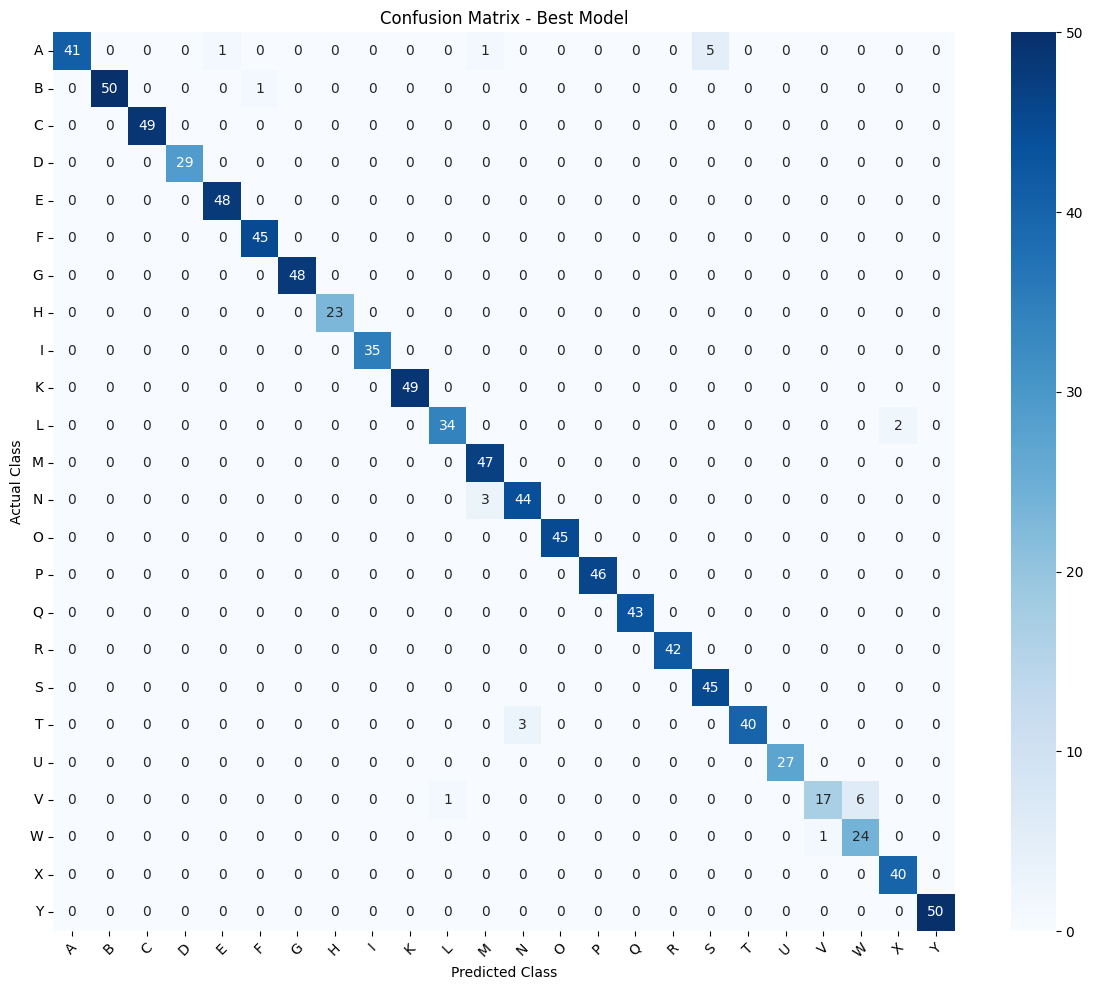

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Reset validation generator
val_data.reset()

# Prediction
y_prob = best_model.predict(val_data, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
y_true = val_data.classes

# Class names
class_names = list(val_data.class_indices.keys())

# Metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print("=" * 50)
print("FINAL MODEL RESULTS")
print("=" * 50)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    cmap='Blues',
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Best Model")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Final Class Names

## Description
The 24 class labels used by the validation generator are displayed.

In [ ]:
# Get class names from validation dataset
classes = list(val_data.class_indices.keys())

print("Number of classes:", len(classes))
print("Classes:", classes)

Number of classes: 24
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


# Inspect MobileNetV2 Convolution Layers

## Description
The MobileNetV2 backbone and its convolution layers are inspected before generating Grad-CAM visualizations.

In [ ]:
backbone = best_model.get_layer('mobilenetv2_1.00_224')

print("Backbone found:", backbone.name)

for layer in backbone.layers:
    if isinstance(layer, tf.keras.layers.Conv2D):
        print(layer.name)

Backbone found: mobilenetv2_1.00_224
Conv1
expanded_conv_project
block_1_expand
block_1_project
block_2_expand
block_2_project
block_3_expand
block_3_project
block_4_expand
block_4_project
block_5_expand
block_5_project
block_6_expand
block_6_project
block_7_expand
block_7_project
block_8_expand
block_8_project
block_9_expand
block_9_project
block_10_expand
block_10_project
block_11_expand
block_11_project
block_12_expand
block_12_project
block_13_expand
block_13_project
block_14_expand
block_14_project
block_15_expand
block_15_project
block_16_expand
block_16_project
Conv_1


#  Grad-CAM Function

## Description
Grad-CAM is implemented to visualize the image regions that contribute to the model's prediction.

In [ ]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os


def make_gradcam_heatmap(
    img_array,
    model,
    last_conv_layer_name='Conv_1',
    pred_index=None
):

    # Get MobileNetV2 backbone
    backbone = model.get_layer('mobilenetv2_1.00_224')

    # Find Conv_1 layer inside backbone
    last_conv_layer = backbone.get_layer(last_conv_layer_name)

    # Make sure backbone has been called
    _ = backbone(img_array)

    # Model: image -> Conv_1 output
    conv_model = tf.keras.Model(
        inputs=backbone.input,
        outputs=last_conv_layer.output
    )

    # Model: image -> final prediction
    prediction_model = model

    with tf.GradientTape() as tape:

        # Get convolution output
        conv_output = conv_model(img_array)

        # Get prediction from original model
        preds = prediction_model(img_array)

        if pred_index is None:
            pred_index = tf.argmax(preds[0])

        class_channel = preds[:, pred_index]

    # Gradients
    grads = tape.gradient(
        class_channel,
        conv_output
    )

    # Global average pooling
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_output = conv_output[0]

    # Weighted activation
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize
    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return heatmap.numpy()


def display_gradcam(
    img_path,
    model,
    class_names,
    last_conv_layer='Conv_1'
):

    # Load image
    img = tf.keras.preprocessing.image.load_img(
        img_path,
        target_size=(224, 224)
    )

    img_array = tf.keras.preprocessing.image.img_to_array(img)

    # Normalize
    img_array = img_array / 255.0

    img_array_exp = np.expand_dims(
        img_array,
        axis=0
    )

    # Prediction
    preds = model.predict(
        img_array_exp,
        verbose=0
    )

    pred_class = np.argmax(preds[0])

    confidence = (
        preds[0][pred_class] * 100
    )

    # Grad-CAM
    heatmap = make_gradcam_heatmap(
        img_array_exp,
        model,
        last_conv_layer
    )

    # Resize heatmap
    heatmap = cv2.resize(
        heatmap,
        (224, 224)
    )

    heatmap_uint8 = np.uint8(
        255 * heatmap
    )

    # Apply colour map
    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Original image
    overlay = (
        img_array * 255
    ).astype(np.uint8)

    # Overlay
    superimposed = cv2.addWeighted(
        overlay,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    # Plot
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(14, 4)
    )

    axes[0].imshow(img_array)
    axes[0].set_title(
        'Original Image'
    )
    axes[0].axis('off')

    axes[1].imshow(
        heatmap,
        cmap='jet'
    )
    axes[1].set_title(
        'Grad-CAM Heatmap'
    )
    axes[1].axis('off')

    axes[2].imshow(
        superimposed
    )
    axes[2].set_title(
        f'Predicted: {class_names[pred_class]} '
        f'({confidence:.1f}%)'
    )
    axes[2].axis('off')

    plt.suptitle(
        'Grad-CAM Explainability — Model Attention Visualization'
    )

    plt.tight_layout()

    os.makedirs(
        'plots',
        exist_ok=True
    )

    plt.savefig(
        'plots/gradcam_result.png',
        dpi=150,
        bbox_inches='tight'
    )

    plt.show()

# Display Final Model and Backbone Summary

## Description
The architecture of the final model and MobileNetV2 backbone is displayed for reference.

In [ ]:
print("BEST MODEL")
print(best_model.summary())

print("\nBACKBONE")
backbone = best_model.get_layer('mobilenetv2_1.00_224')
print(backbone.summary())

BEST MODEL


Model: "MobileNetV2_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │         6,168 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,682,698 (21.68 MB)

 Trainable params: 1,542,744 (5.89 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 1,206,080 (4.60 MB)

 Non-trainable params: 1,051,904 (4.01 MB)

None


#  Inspect Final Model Layers

## Description
The layers of the final model are listed to understand the structure of the MobileNetV2 classifier head.

In [ ]:
for i, layer in enumerate(best_model.layers):
    print(i, layer.name, type(layer).__name__)

0 mobilenetv2_1.00_224 Functional
1 global_average_pooling2d GlobalAveragePooling2D
2 batch_normalization BatchNormalization
3 dense_2 Dense
4 dropout_1 Dropout
5 dense_3 Dense


# Final Grad-CAM Implementation

## Description
A Grad-CAM heatmap is generated from the MobileNetV2 feature maps and combined with the original image.

In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt


def make_gradcam_heatmap(img_array, model, pred_index=None):

    # Get model components
    backbone = model.get_layer('mobilenetv2_1.00_224')
    global_pool = model.get_layer('global_average_pooling2d')
    batch_norm = model.get_layer('batch_normalization')
    dense2 = model.get_layer('dense_2')
    dropout = model.get_layer('dropout_1')
    dense3 = model.get_layer('dense_3')

    # Forward pass with GradientTape
    with tf.GradientTape() as tape:

        # Backbone feature maps
        features = backbone(img_array, training=False)

        # Watch feature maps
        tape.watch(features)

        # Classifier head
        x = global_pool(features)
        x = batch_norm(x, training=False)
        x = dense2(x)
        x = dropout(x, training=False)
        preds = dense3(x, training=False)

        # Predicted class
        if pred_index is None:
            pred_index = tf.argmax(preds[0])

        class_channel = preds[:, pred_index]

    # Gradient of class score with respect to feature maps
    grads = tape.gradient(class_channel, features)

    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    features = features[0]

    # Grad-CAM
    heatmap = tf.reduce_sum(
        features * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)

    heatmap = heatmap / (max_value + 1e-8)

    return heatmap.numpy()


def display_gradcam(img_path, model, class_names):

    # Load image
    img = tf.keras.preprocessing.image.load_img(
        img_path,
        target_size=(224, 224)
    )

    img_array = tf.keras.preprocessing.image.img_to_array(img)

    # Normalize
    img_array = img_array / 255.0

    # Add batch dimension
    img_array_exp = np.expand_dims(
        img_array,
        axis=0
    )

    # Prediction
    preds = model.predict(
        img_array_exp,
        verbose=0
    )

    pred_class = np.argmax(preds[0])

    confidence = preds[0][pred_class] * 100

    # Grad-CAM
    heatmap = make_gradcam_heatmap(
        img_array_exp,
        model,
        pred_index=pred_class
    )

    # Resize heatmap
    heatmap = cv2.resize(
        heatmap,
        (224, 224)
    )

    # Convert to 0-255
    heatmap_uint8 = np.uint8(
        255 * heatmap
    )

    # Apply color map
    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Original image
    original = np.uint8(
        img_array * 255
    )

    # Overlay
    superimposed = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    # Display
    fig, axes = plt.subplots(
        1, 3,
        figsize=(14, 4)
    )

    axes[0].imshow(img_array)
    axes[0].set_title(
        'Original Image'
    )
    axes[0].axis('off')

    axes[1].imshow(
        heatmap,
        cmap='jet'
    )
    axes[1].set_title(
        'Grad-CAM Heatmap'
    )
    axes[1].axis('off')

    axes[2].imshow(
        superimposed
    )
    axes[2].set_title(
        f'Predicted: {class_names[pred_class]} '
        f'({confidence:.1f}%)'
    )
    axes[2].axis('off')

    plt.suptitle(
        'Grad-CAM Explainability - Model Attention Visualization'
    )

    plt.tight_layout()

    # Create plots folder
    os.makedirs(
        'plots',
        exist_ok=True
    )

    plt.savefig(
        'plots/gradcam_result.png',
        dpi=150,
        bbox_inches='tight'
    )

    plt.show()

# Grad-CAM Examples

## Description
Grad-CAM examples are generated for selected sign classes such as **A, B, K and Y**. This provides a visual explanation of the regions used by the model.

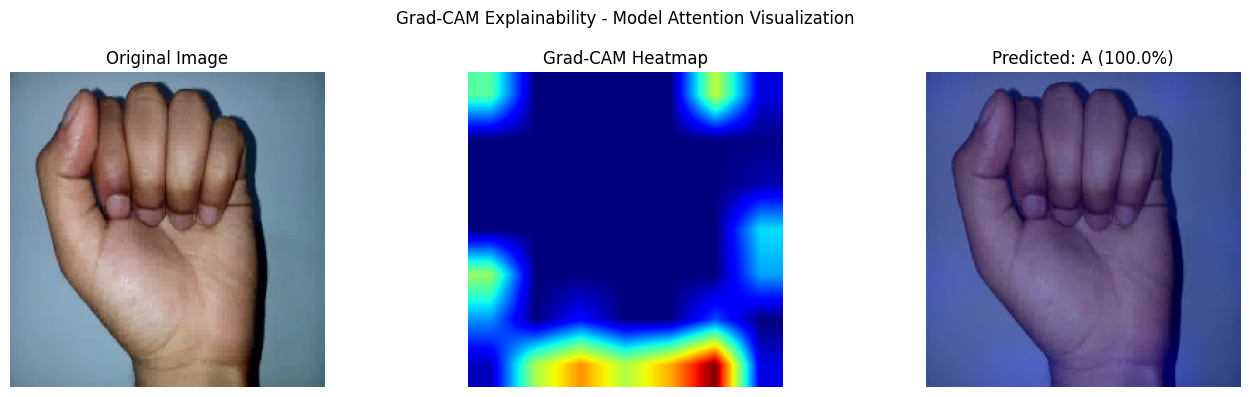

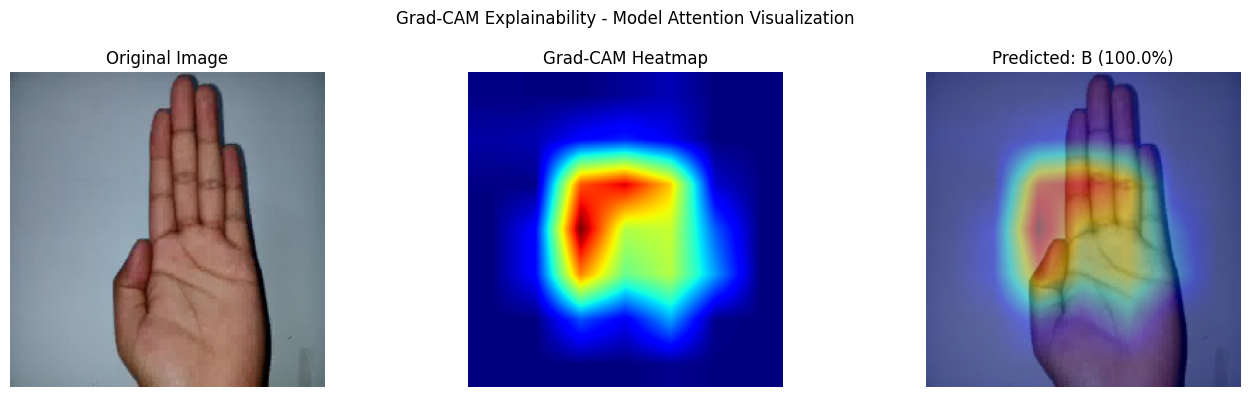

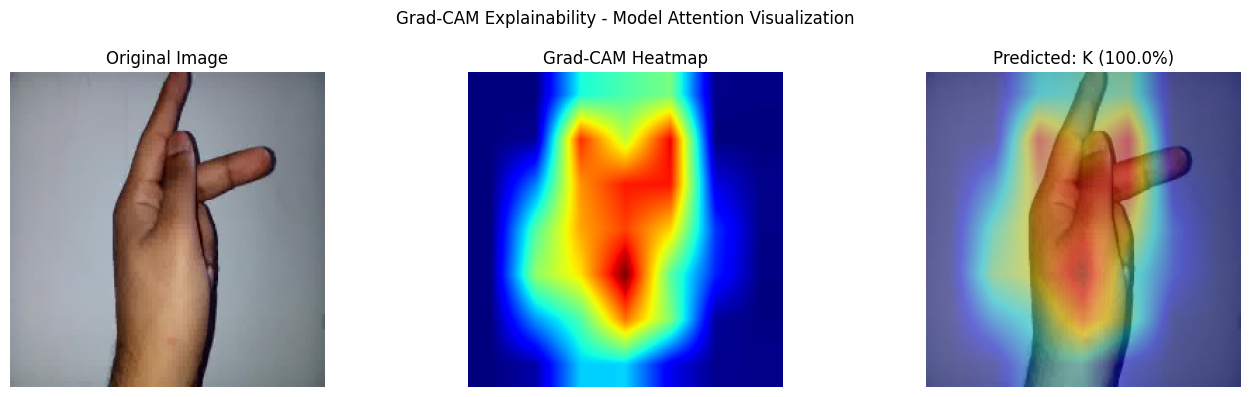

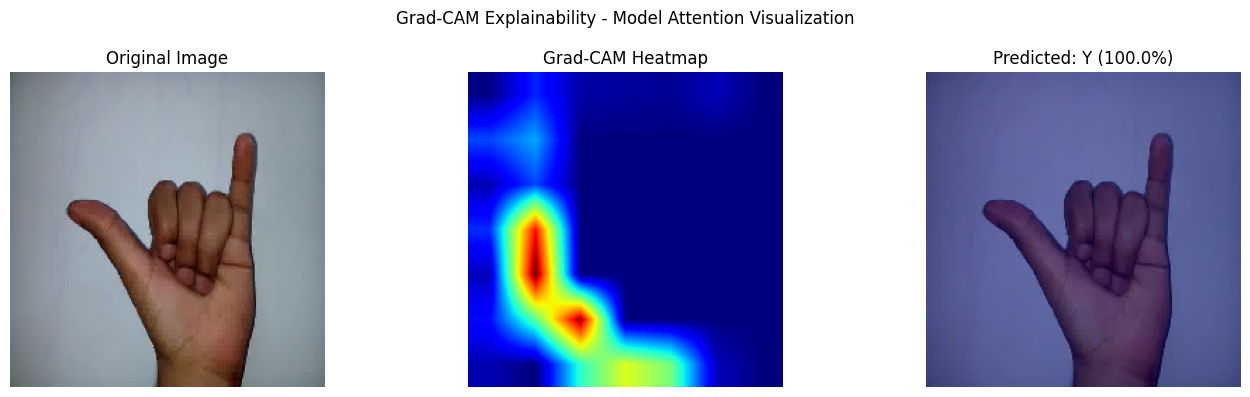

In [ ]:
classes = list(val_data.class_indices.keys())

sample_classes = ['A', 'B', 'K', 'Y']

for cls in sample_classes:

    cls_path = os.path.join(
        data_path,
        cls
    )

    files = os.listdir(cls_path)

    if len(files) == 0:
        print(f"No images found for class {cls}")
        continue

    sample = os.path.join(
        cls_path,
        files[0]
    )

    display_gradcam(
        sample,
        best_model,
        classes
    )

#  Multi-Class ROC Curve

## Description
ROC curves and AUC values are calculated for all 24 Indian Sign Language classes using the final model predictions.

Found 985 images belonging to 24 classes.
Number of classes: 24
Number of images: 985
31/31 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step


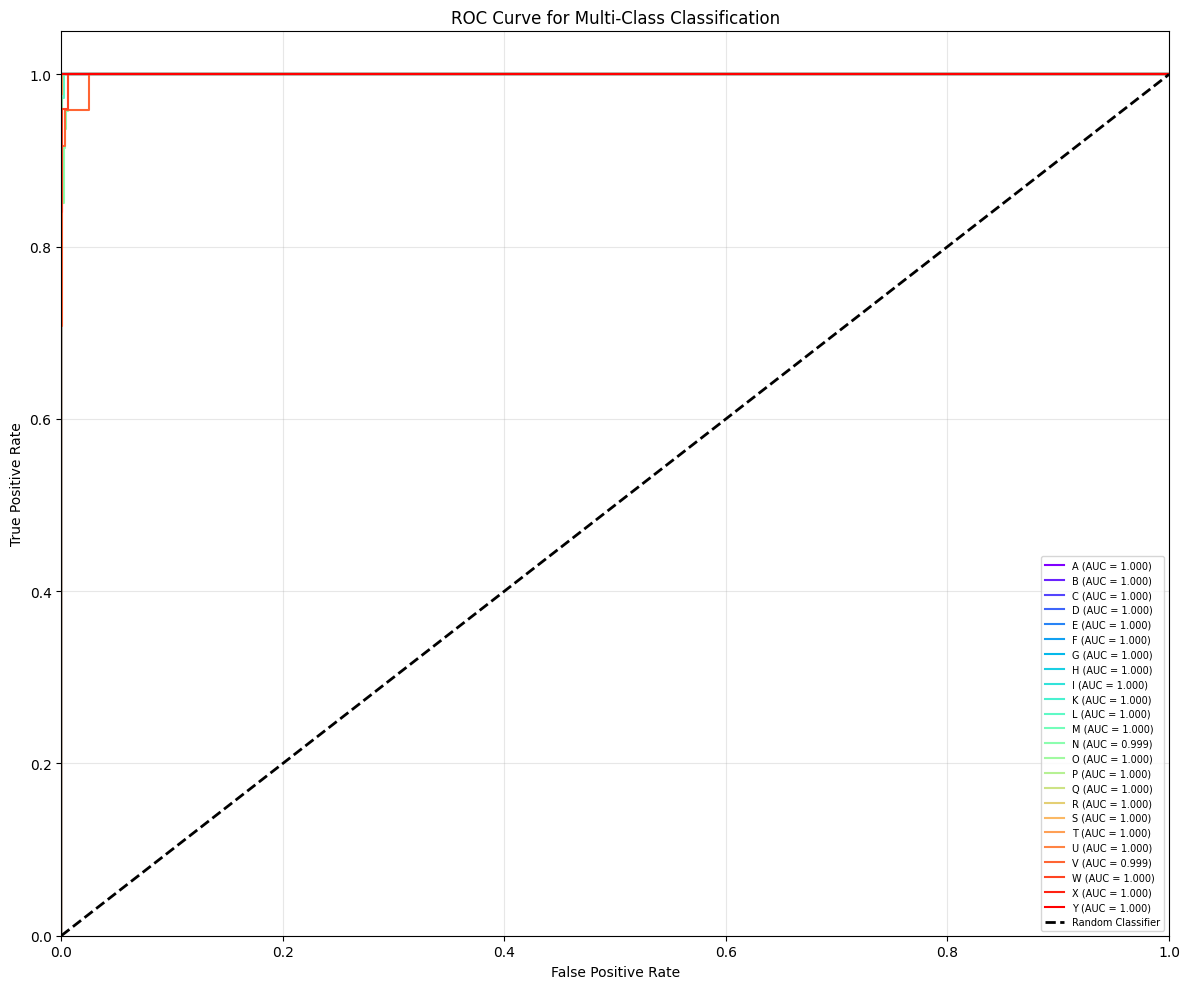

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt

# Dataset path
data_path = "/content/drive/MyDrive/IndisignLanguageRecognition/Data"

# Create test/evaluation generator
datagen_test = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

test_data = datagen_test.flow_from_directory(
    data_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# Number of classes
n_classes = len(test_data.class_indices)

print("Number of classes:", n_classes)
print("Number of images:", test_data.samples)

# Reset generator
test_data.reset()

# Model predictions
y_pred_proba = best_model.predict(
    test_data,
    verbose=1
)

# True labels
y_true = test_data.classes

# Convert labels to binary
y_test_bin = label_binarize(
    y_true,
    classes=range(n_classes)
)

# ROC values
fpr = {}
tpr = {}
roc_auc = {}

for i in range(n_classes):

    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i],
        y_pred_proba[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

# Plot ROC curves
plt.figure(figsize=(12, 10))

colors = plt.cm.rainbow(
    np.linspace(0, 1, n_classes)
)

class_names = list(
    test_data.class_indices.keys()
)

for i, color in zip(
    range(n_classes),
    colors
):

    plt.plot(
        fpr[i],
        tpr[i],
        color=color,
        lw=1.5,
        label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})'
    )

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    lw=2,
    label='Random Classifier'
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title(
    'ROC Curve for Multi-Class Classification'
)

plt.legend(
    loc='lower right',
    fontsize=7
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    'plots/roc_curve.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

#  Final Classification Report

## Description
The final classification report provides class-wise precision, recall, F1-score and support for the selected MobileNetV2 model.

In [ ]:
# ============================================================
# FINAL CLASSIFICATION REPORT - BEST MODEL
# ============================================================

test_data.reset()

y_pred_final = np.argmax(
    best_model.predict(test_data, verbose=1),
    axis=1
)

y_true_final = test_data.classes

classes = list(
    test_data.class_indices.keys()
)

print("=" * 60)
print("FINAL CLASSIFICATION REPORT - MobileNetV2")
print("=" * 60)

print(
    classification_report(
        y_true_final,
        y_pred_final,
        target_names=classes,
        digits=4
    )
)

31/31 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step
FINAL CLASSIFICATION REPORT - MobileNetV2
              precision    recall  f1-score   support

           A     1.0000    0.8542    0.9213        48
           B     1.0000    0.9804    0.9901        51
           C     1.0000    1.0000    1.0000        49
           D     1.0000    1.0000    1.0000        29
           E     0.9796    1.0000    0.9897        48
           F     0.9783    1.0000    0.9890        45
           G     1.0000    1.0000    1.0000        48
           H     1.0000    1.0000    1.0000        23
           I     1.0000    1.0000    1.0000        35
           K     1.0000    1.0000    1.0000        49
           L     0.9714    0.9444    0.9577        36
           M     0.9216    1.0000    0.9592        47
           N     0.9362    0.9362    0.9362        47
           O     1.0000    1.0000    1.0000        45
           P     1.0000    1.0000    1.0000        46
           Q     1.0000    1.0000    1.0000        43


# Final Accuracy Visualization

## Description
The final verified accuracy of the selected model is displayed as a simple bar chart.

**Final Accuracy: 97.56%**

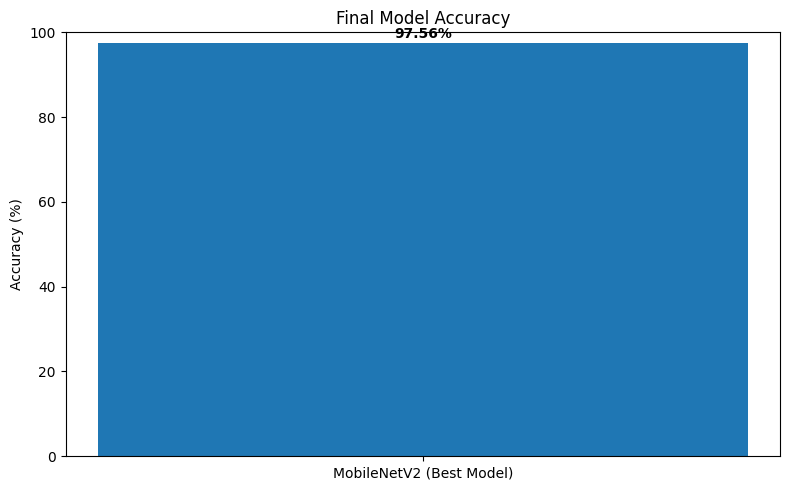

In [ ]:
# Final Accuracy Bar Chart - Best Model

import matplotlib.pyplot as plt

# Verified final accuracy
model_name = "MobileNetV2 (Best Model)"
accuracy = 97.56

plt.figure(figsize=(8, 5))

bar = plt.bar([model_name], [accuracy])

plt.title("Final Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.text(
    bar[0].get_x() + bar[0].get_width() / 2,
    accuracy + 1,
    f"{accuracy:.2f}%",
    ha="center",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#  Final Verified Model Result

## Description
This cell records the final verified result used for project reporting.

**MobileNetV2 (Best Model) – 97.56% Accuracy**

       FINAL MODEL RESULTS
                   Model  Accuracy (%)
MobileNetV2 (Best Model)         97.56


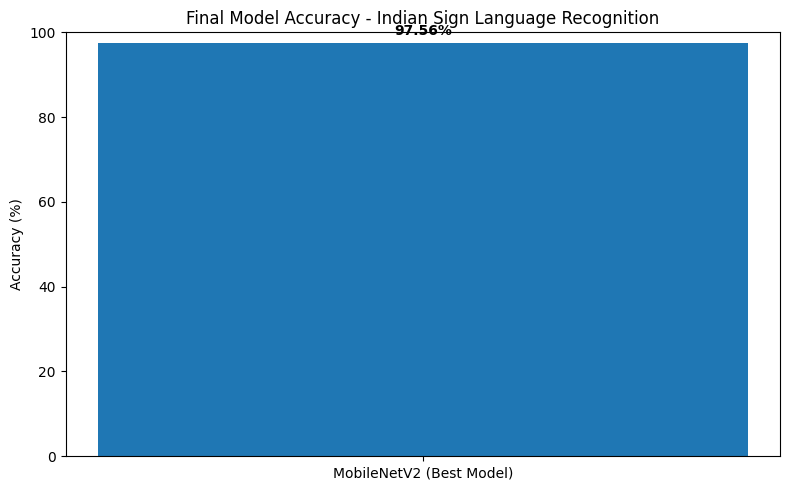

In [ ]:
# Final verified model result

import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs('plots', exist_ok=True)

final_results = {
    'MobileNetV2 (Best Model)': 97.56
}

results_df = pd.DataFrame(
    list(final_results.items()),
    columns=['Model', 'Accuracy (%)']
)

print("=" * 50)
print("       FINAL MODEL RESULTS")
print("=" * 50)
print(results_df.to_string(index=False))

# Bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    results_df['Model'],
    results_df['Accuracy (%)']
)

for bar, val in zip(bars, results_df['Accuracy (%)']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        val + 1,
        f'{val:.2f}%',
        ha='center',
        va='bottom',
        fontweight='bold'
    )

plt.title('Final Model Accuracy - Indian Sign Language Recognition')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

plt.tight_layout()
plt.savefig(
    'plots/final_comparison.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

#  Final Confusion Matrix

## Description
The final confusion matrix summarizes the relationship between actual and predicted sign classes. A strong diagonal pattern indicates correct classification.

31/31 ━━━━━━━━━━━━━━━━━━━━ 31s 992ms/step


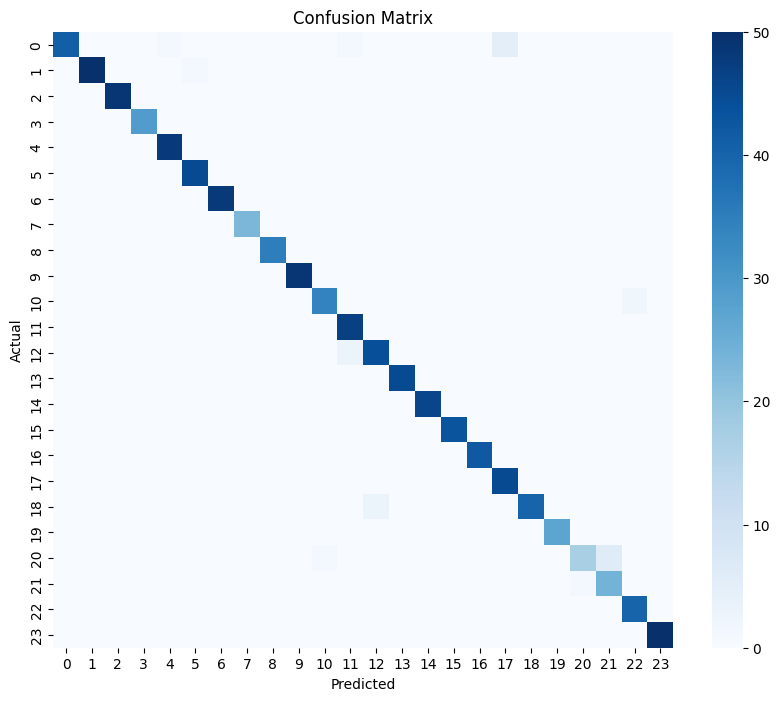

In [ ]:
from sklearn.metrics import confusion_matrix
y_pred_all = np.argmax(best_model.predict(test_data, verbose=1), axis=1)
y_true_all = test_data.classes
cm = confusion_matrix(y_true_all, y_pred_all)
# Plot (faster visualization)
plt.figure(figsize=(10,8))
sns.heatmap(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#  Conclusion

## Description
This project demonstrates the use of Computer Vision, Deep Learning and Machine Learning for Indian Sign Language recognition.

The dataset contains **4,972 images across 24 sign classes**. The workflow includes EDA, image preprocessing, data augmentation, CNN and transfer-learning models, feature extraction and traditional Machine Learning comparison.

The final saved **Fine-Tuned MobileNetV2** model was evaluated on **985 validation images** and achieved:

- **Accuracy: 97.56%**
- **Precision: 97.72%**
- **Recall: 97.56%**
- **F1-Score: 97.53%**

The project also includes confusion-matrix analysis, Grad-CAM visualization and ROC/AUC analysis.

#  Future Scope

## Description
The current project focuses on static image-based sign recognition. It can be extended into a real-time and more practical communication system.

Possible future improvements include:

- Real-time sign recognition using a webcam.
- Adding more Indian Sign Language signs and words.
- Recognition of sequences of signs for word/sentence generation.
- Text-to-Speech output for recognized signs.
- Mobile application deployment.
- More diverse training images from different users, backgrounds and lighting conditions.
- Real-time hand tracking using MediaPipe.
- Model optimization for mobile and edge devices.

#  Final Project Workflow

## Description

**Dataset → Data Exploration → Image Preprocessing → Data Augmentation → CNN / MobileNetV2 / EfficientNetB0 → Feature Extraction → SVM / KNN / Random Forest / Logistic Regression → Model Comparison → Final MobileNetV2 Evaluation → Confusion Matrix → Grad-CAM → ROC/AUC → Conclusion**

#  Final Project Result

## Description

The final verified result reported by the notebook is:

**Model:** Fine-Tuned MobileNetV2  
**Classes:** 24  
**Validation Images:** 985  
**Accuracy:** 97.56%  
**Precision:** 97.72%  
**Recall:** 97.56%  
**F1-Score:** 97.53%

This result is used as the final project result for submission.
